In [1]:
!pip install -q pypdf pandas numpy matplotlib seaborn
!pip install -q sentence-transformers faiss-cpu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pypdf import PdfReader
print("All libraries installed successfully!")

All libraries installed successfully!


In [2]:
import torch

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. CPU will be used.")

GPU Available: Tesla T4


# **Pdf Loading**

In [3]:
from google.colab import files
uploaded = files.upload()
pdf_path = list(uploaded.keys())[0]
print("Uploaded file:", pdf_path)

Saving Cambodia_IMF_Financial_Analysis.pdf to Cambodia_IMF_Financial_Analysis.pdf
Uploaded file: Cambodia_IMF_Financial_Analysis.pdf


In [4]:
from pypdf import PdfReader
reader = PdfReader(pdf_path)
total_pages = len(reader.pages)
print("Total PDF pages:", total_pages)
raw_text = ""
page_texts = []
for page_number, page in enumerate(reader.pages, start=1):
    text = page.extract_text() or ""
    page_texts.append(text)
    raw_text += text + "\n"
print("\nText extraction completed!")
print("Total characters:", len(raw_text))
print("Total words:", len(raw_text.split()))
print("\n--- EXTRACTED TEXT SAMPLE ---\n")
print(raw_text[:3000])

Total PDF pages: 114

Text extraction completed!
Total characters: 242516
Total words: 35847

--- EXTRACTED TEXT SAMPLE ---

 
© 2024 International Monetary Fund 
IMF Country Report No. 24/36 
CAMBODIA 
2023 ARTICLE IV CONSULTATION—PRESS RELEASE; 
AND STAFF REPORT 
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions 
with members, usually every year. In the context of the 2023 Article IV consultation with 
Cambodia, the following documents have been released and are included in this package: 
 
• A Press Release. 
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s 
consideration on a lapse-of-time basis following discussions that ended on October 
31, 2023, with the officials of Cambodia on economic developments and policies. 
Based on information available at the time of these discussions, the staff report was 
completed on December 12, 2023. 
• An Informational Annex prepared by the IMF staff. 
• A Debt Sustainability

In [5]:
for i in range(min(10, total_pages)):
    print(f"\nPAGE {i+1}")
    print("-" * 50)
    print(page_texts[i][:500])


PAGE 1
--------------------------------------------------
 
© 2024 International Monetary Fund 
IMF Country Report No. 24/36 
CAMBODIA 
2023 ARTICLE IV CONSULTATION—PRESS RELEASE; 
AND STAFF REPORT 
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions 
with members, usually every year. In the context of the 2023 Article IV consultation with 
Cambodia, the following documents have been released and are included in this package: 
 
• A Press Release. 
• The Staff Report prepared by a staff team of the IMF for the Execu

PAGE 2
--------------------------------------------------
PR24/31 
 
IMF Executive Board Concludes 2023 Article IV Consultation with 
Cambodia 
FOR IMMEDIATE RELEASE 
Washington, DC – January 31, 2024: The Executive Board of the International Monetary Fund (IMF) 
concluded the Article IV consultation1 with Cambodia.  
Cambodia is on a recovery trajectory post-pandemic, with a GDP growth of 5.2 percent in 2022. The 
manufacturing sector

# **Text Cleaning**

In [6]:
import re
import html
cleaned_text = html.unescape(raw_text)
cleaned_lines = []
for line in cleaned_text.splitlines():
    line = line.strip()
    if not line:
        continue
    if line.upper() in ["CAMBODIA", "INTERNATIONAL MONETARY FUND"]:
        continue
    if re.fullmatch(r"\d+", line):
        continue
    cleaned_lines.append(line)
cleaned_text = "\n".join(cleaned_lines)
cleaned_text = re.sub(r"(?<=\w)-\n(?=\w)", "", cleaned_text)
cleaned_text = re.sub(r"[ \t]+", " ", cleaned_text)
cleaned_text = re.sub(r"\n{3,}", "\n\n", cleaned_text)
print("TEXT CLEANING COMPLETED")
print("Original characters:", len(raw_text))
print("Cleaned characters:", len(cleaned_text))
print("Cleaned words:", len(cleaned_text.split()))
print("\n--- CLEANED TEXT SAMPLE ---\n")
print(cleaned_text[:3000])

TEXT CLEANING COMPLETED
Original characters: 242516
Cleaned characters: 233313
Cleaned words: 35421

--- CLEANED TEXT SAMPLE ---

© 2024 International Monetary Fund
IMF Country Report No. 24/36
2023 ARTICLE IV CONSULTATION—PRESS RELEASE;
AND STAFF REPORT
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions
with members, usually every year. In the context of the 2023 Article IV consultation with
Cambodia, the following documents have been released and are included in this package:
• A Press Release.
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s
consideration on a lapse-of-time basis following discussions that ended on October
31, 2023, with the officials of Cambodia on economic developments and policies.
Based on information available at the time of these discussions, the staff report was
completed on December 12, 2023.
• An Informational Annex prepared by the IMF staff.
• A Debt Sustainability Analysis prepared by t

In [7]:
!pip install -q tiktoken

In [8]:
import tiktoken
tokenizer = tiktoken.get_encoding("cl100k_base")
tokens = tokenizer.encode(cleaned_text)
CHUNK_SIZE = 400
OVERLAP = 50
STEP = CHUNK_SIZE - OVERLAP
chunks = []
for start in range(0, len(tokens), STEP):
    end = min(start + CHUNK_SIZE, len(tokens))
    chunk_tokens = tokens[start:end]
    chunk_text = tokenizer.decode(chunk_tokens)
    chunks.append({
        "chunk_id": len(chunks) + 1,
        "start_token": start,
        "end_token": end,
        "token_count": len(chunk_tokens),
        "text": chunk_text
    })
    if end == len(tokens):
        break
chunks_df = pd.DataFrame(chunks)
print("TOKEN CHUNKING COMPLETED")
print("Total tokens:", len(tokens))
print("Total chunks:", len(chunks_df))
print("Average tokens per chunk:", round(chunks_df["token_count"].mean(), 2))
print("\n--- FIRST CHUNK ---\n")
print(chunks_df.iloc[0]["text"])

TOKEN CHUNKING COMPLETED
Total tokens: 61895
Total chunks: 177
Average tokens per chunk: 399.41

--- FIRST CHUNK ---

© 2024 International Monetary Fund
IMF Country Report No. 24/36
2023 ARTICLE IV CONSULTATION—PRESS RELEASE;
AND STAFF REPORT
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions
with members, usually every year. In the context of the 2023 Article IV consultation with
Cambodia, the following documents have been released and are included in this package:
• A Press Release.
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s
consideration on a lapse-of-time basis following discussions that ended on October
31, 2023, with the officials of Cambodia on economic developments and policies.
Based on information available at the time of these discussions, the staff report was
completed on December 12, 2023.
• An Informational Annex prepared by the IMF staff.
• A Debt Sustainability Analysis prepared by the staffs of

In [9]:
print("CHUNK VALIDATION")
print("Total chunks:", len(chunks))
print("\nFirst 5 chunks:")
display(chunks_df[["chunk_id", "start_token",
                   "end_token", "token_count"]].head())
print("\nLast chunk token count:",
      chunks_df.iloc[-1]["token_count"])
print("\nOverlap configured:", OVERLAP)
print("Chunk size configured:", CHUNK_SIZE)

CHUNK VALIDATION
Total chunks: 177

First 5 chunks:


,chunk_id,start_token,end_token,token_count
0,1,0,400,400
1,2,350,750,400
2,3,700,1100,400
3,4,1050,1450,400
4,5,1400,1800,400



Last chunk token count: 295

Overlap configured: 50
Chunk size configured: 400


In [10]:
!pip install -q google-genai

In [13]:
from google import genai
from google.colab import userdata
GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
client = genai.Client(api_key=GEMINI_API_KEY)
MODEL_NAME = "gemini-2.5-flash"
print("Gemini configured successfully!")

Gemini configured successfully!


In [15]:
MODEL_NAME = "gemini-3.8-flash"

print("Updated model:", MODEL_NAME)

Updated model: gemini-3.8-flash


In [17]:
import time

batch_size = 15
total_batches = (len(chunks) + batch_size - 1) // batch_size

start_index = len(batch_summaries) * batch_size

print("Already completed:", len(batch_summaries))
print("Resuming from batch:", len(batch_summaries) + 1)

for i in range(start_index, len(chunks), batch_size):
    batch = chunks[i:i + batch_size]

    source_text = "\n\n".join(
        chunk["text"] for chunk in batch
    )

    prompt = f"""
You are an IMF economic research analyst.

Analyse these extracts from the IMF Cambodia Country Report No. 24/36.

Identify:
1. Economic growth and GDP.
2. Inflation and prices.
3. Monetary and fiscal policies.
4. Banking and financial stability.
5. Public debt and external risks.
6. Labour market and employment.
7. Economic vulnerabilities and IMF recommendations.

Use only information supported by the text.
Preserve numerical values and reporting periods.
Distinguish actual figures from forecasts.
Do not invent missing information.

SOURCE TEXT:
{source_text}
"""

    for attempt in range(5):
        try:
            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt
            )

            batch_summaries.append(response.text)

            print(f"Completed batch {len(batch_summaries)} of {total_batches}")
            break

        except Exception as e:
            print("Temporary error:", e)

            if attempt < 4:
                time.sleep(20 * (attempt + 1))
            else:
                raise

    time.sleep(5)

print("Total completed batches:", len(batch_summaries))

Already completed: 2
Resuming from batch: 3
Temporary error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Completed batch 3 of 12
Completed batch 4 of 12
Completed batch 5 of 12
Completed batch 6 of 12
Temporary error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Temporary error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Temporary error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Completed ba

In [18]:
import json

combined_notes = "\n\n".join(batch_summaries)

with open("Cambodia_Batch_Summaries.json", "w") as f:
    json.dump(
        {
            "country": "Cambodia",
            "report_number": "24/36",
            "model": MODEL_NAME,
            "total_batches": len(batch_summaries),
            "batch_summaries": batch_summaries
        },
        f,
        indent=4
    )

print("Batch summaries saved successfully!")
print("Total batches:", len(batch_summaries))
print("Combined notes:", len(combined_notes), "characters")

Batch summaries saved successfully!
Total batches: 12
Combined notes: 96331 characters


In [19]:
final_prompt = f"""
You are an economic research analyst.

Prepare a comprehensive executive summary of the IMF Cambodia Country Report No. 24/36.

Organise the summary under these headings:

1. Economic Overview
2. GDP Growth and Recovery
3. Inflation and Monetary Policy
4. Fiscal Position and Public Debt
5. Banking and Financial Stability
6. Labour Market and Employment
7. Major Economic Risks
8. IMF Recommendations

Requirements:
- Approximately 500–700 words.
- Use only evidence contained in the supplied batch summaries.
- Preserve numerical values and reporting periods.
- Distinguish historical figures from forecasts.
- Do not invent missing statistics.
- Use professional academic language.
- Mention any areas where the available evidence is insufficient.

SOURCE NOTES:
{combined_notes}
"""

response = client.models.generate_content(
    model=MODEL_NAME,
    contents=final_prompt
)

executive_summary = response.text

print(executive_summary)

### 1. Economic Overview
Cambodia continues its post-pandemic recovery, though output remains approximately 14 percent below its pre-pandemic trend, which had averaged around 7 percent annual growth over the preceding decade. Per capita GDP stood at US$ 1,546 in 2022. The output gap is projected to close and turn positive by 2025. While domestic activity is supported by recovering services and non-garment manufacturing, the economy faces headwinds from extensive private sector leverage, structural external vulnerabilities, and geopolitical fragmentation.

### 2. GDP Growth and Recovery
Following a contraction of -3.1 percent in 2020, real GDP expanded by 3.0 percent in 2021 and 5.2 percent in 2022, with nominal GDP reaching KHR 121,030 billion (US$ 28,818 million). Growth was estimated at 5.3 percent in 2023 (nominal GDP of US$ 30,872 million) and is projected to accelerate to 6.0 percent in 2024, 6.4 percent in 2025, and average approximately 6.3 to 6.5 percent through 2028. 

Histori

In [20]:
with open("Cambodia_Executive_Summary.json", "w") as f:
    json.dump(
        {
            "country": "Cambodia",
            "report_number": "24/36",
            "model": MODEL_NAME,
            "executive_summary": executive_summary
        },
        f,
        indent=4
    )

print("Executive summary saved successfully!")

Executive summary saved successfully!


In [21]:
recommendation_prompt = f"""
You are an IMF economic research analyst.

Using the source notes below, prepare Section 8: IMF Recommendations
for the Cambodia IMF Country Report No. 24/36.

Identify the report's actual recommendations concerning:
1. Fiscal policy and public finances.
2. Monetary and exchange rate policy.
3. Banking supervision and financial stability.
4. Structural reforms and economic diversification.
5. Data quality and statistical capacity.

Requirements:
- Include only recommendations supported by the source notes.
- Do not invent policies or recommendations.
- Distinguish IMF recommendations from actions already implemented.
- Use concise academic language.
- If the notes do not provide enough evidence for a topic, state that.

SOURCE NOTES:
{combined_notes}
"""

response = client.models.generate_content(
    model=MODEL_NAME,
    contents=recommendation_prompt
)

recommendations_section = response.text

print(recommendations_section)

### Section 8: IMF Recommendations

This section details the policy recommendations of the International Monetary Fund (IMF) for Cambodia, based on IMF Country Report No. 24/36. It distinguishes policy advice from actions already implemented by the authorities (such as the June 2022 expiration of loan forbearance, the February 2023 removal from the FATF grey list, and the 2023 enactment of laws on taxation, procurement, and public finance).

---

### 1. Fiscal Policy and Public Finances

* **Fiscal Stance and Consolidation:** Following the expansionary stance in 2023, the authorities should return to a neutral fiscal stance in 2024 and execute a gradual medium-term fiscal consolidation to rebuild depleted fiscal buffers and protect macroeconomic stability.
* **Expenditure Rationalization and Social Safety Nets:** Phased-out temporary, untargeted crisis transfers should be permanently wound down, while targeted social safety nets for poor and vulnerable households must be institutionali

In [22]:
executive_summary = executive_summary + "\n\n### 8. IMF Recommendations\n" + recommendations_section

with open("Cambodia_Executive_Summary.json", "w") as f:
    json.dump(
        {
            "country": "Cambodia",
            "report_number": "24/36",
            "model": MODEL_NAME,
            "executive_summary": executive_summary
        },
        f,
        indent=4
    )

print("Complete executive summary saved!")
print("Word count:", len(executive_summary.split()))

Complete executive summary saved!
Word count: 2127


In [23]:
evaluation_prompt = f"""
You are an independent evaluation reviewer assessing an AI-generated
executive summary against source material from an IMF country report.

Evaluate the summary using the supplied source notes.

EXECUTIVE SUMMARY:
{executive_summary}

SOURCE NOTES:
{combined_notes}

Evaluate these criteria:

1. Factual alignment: Are the figures and statements supported?
2. Completeness: Are important economic themes and risks covered?
3. Consistency: Are there contradictions or conflicting figures?
4. Historical versus forecast accuracy: Are actuals and projections distinguished?
5. Unsupported claims: Identify claims not supported by the source notes.
6. Missing information: Identify important omissions.

Provide:
- A score out of 10 for each criterion.
- Specific examples of errors or omissions.
- Suggested corrections.
- An overall assessment.

Do not assume that a claim is correct merely because it appears in the summary.
"""

evaluation_response = client.models.generate_content(
    model=MODEL_NAME,
    contents=evaluation_prompt
)

evaluation_result = evaluation_response.text

print(evaluation_result)

### Evaluation of the Executive Summary

---

### Criterion-by-Criterion Evaluation

#### 1. Factual Alignment
* **Score: 9 / 10**
* **Assessment:** The factual accuracy across macroeconomic metrics is exceptionally high. Nearly all figures—including real GDP growth, nominal GDP values, inflation outturns/peaks, reserve requirement ratios, fiscal balances, debt-to-GDP levels, corporate interest coverage ratios (ICR), non-performing loans (NPLs), and spillover elasticities—match the source notes exactly.
* **Specific Error / Imprecision:**
  * In **Section 4**, the summary states: *"Public and publicly guaranteed (PPG) debt was 34.8 percent of GDP in 2022 (US$ 9,971 million, almost entirely concessional external debt)"*. In the source notes, US$ 9,971 million represents the *external* public debt (34.8% of GDP), whereas total PPG debt is reported as either 34.8% or 35.0% of GDP (with domestic debt accounting for <0.1% of GDP / US$ 17.5 million). Conflating the external debt stock with t

In [25]:
evaluation_prompt = f"""
You are an academic evaluation reviewer assessing an AI-generated
executive summary of IMF Country Report No. 24/36 on Cambodia.

Evaluate the executive summary against the source notes provided.

EXECUTIVE SUMMARY:
{executive_summary}

SOURCE NOTES:
{combined_notes}

Assess the following criteria:

1. Factual alignment: Are the reported figures and statements supported?
2. Completeness: Are the major economic themes and IMF recommendations covered?
3. Consistency: Are there contradictions or conflicting figures?
4. Historical and forecast accuracy: Are actual values distinguished from projections?
5. Unsupported claims: Identify statements that require verification.
6. Missing information: Identify important omissions.
7. Recommendation accuracy: Are recommendations distinguished from actions already implemented?

For each criterion:
- Give a score out of 10.
- Explain the score.
- Identify specific examples.

Finally provide:
- Overall score out of 10.
- Main weaknesses.
- Suggested corrections.
- Overall evaluation conclusion.

Do not assume that a statement is correct merely because it appears in the executive summary.
"""

evaluation_response = client.models.generate_content(
    model=MODEL_NAME,
    contents=evaluation_prompt
)

evaluation_result = evaluation_response.text

print(evaluation_result)

Here is an academic evaluation and verification of the AI-generated executive summary against the provided source extracts from IMF Country Report No. 24/36.

---

### Detailed Criterion-by-Criterion Evaluation

#### 1. Factual Alignment: Are the reported figures and statements supported?
* **Score:** 9.5 / 10
* **Explanation:** The vast majority of quantitative and qualitative data points closely replicate figures from the source notes. Minor conflations exist between total deficit and primary deficit definitions, but numerical precision across GDP, fiscal accounts, external accounts, monetary statistics, stress simulations, and FSIs is exceptionally high.
* **Specific Examples:**
  * *Accurate alignments:* Nominal GDP figures (KHR 121,030 bn in 2022; US$ 30,872 mn in 2023), real GDP growth paths (-3.1%, 3.0%, 5.2%, 5.3%, 6.0%), per capita GDP ($1,546), inflation swings (peaking at 7.8% in June 2022, troughing at 0.07% in June 2023, 3.9% in October 2023), REER overvaluation ranges (11

In [26]:
with open("Cambodia_AI_Evaluation.json", "w") as f:
    json.dump(
        {
            "country": "Cambodia",
            "report_number": "24/36",
            "model": MODEL_NAME,
            "evaluation": evaluation_result
        },
        f,
        indent=4
    )

print("AI evaluation saved successfully!")

AI evaluation saved successfully!


In [27]:
executive_summary_clean = (
    executive_summary.split("### 8. IMF Recommendations", 1)[0].rstrip()
    + "\n\n"
    + recommendations_section.strip()
)

print(executive_summary_clean)

### 1. Economic Overview
Cambodia continues its post-pandemic recovery, though output remains approximately 14 percent below its pre-pandemic trend, which had averaged around 7 percent annual growth over the preceding decade. Per capita GDP stood at US$ 1,546 in 2022. The output gap is projected to close and turn positive by 2025. While domestic activity is supported by recovering services and non-garment manufacturing, the economy faces headwinds from extensive private sector leverage, structural external vulnerabilities, and geopolitical fragmentation.

### 2. GDP Growth and Recovery
Following a contraction of -3.1 percent in 2020, real GDP expanded by 3.0 percent in 2021 and 5.2 percent in 2022, with nominal GDP reaching KHR 121,030 billion (US$ 28,818 million). Growth was estimated at 5.3 percent in 2023 (nominal GDP of US$ 30,872 million) and is projected to accelerate to 6.0 percent in 2024, 6.4 percent in 2025, and average approximately 6.3 to 6.5 percent through 2028. 

Histori

In [28]:
with open("Cambodia_Executive_Summary_Final.json", "w") as f:
    json.dump(
        {
            "country": "Cambodia",
            "report_number": "24/36",
            "model": MODEL_NAME,
            "executive_summary": executive_summary_clean
        },
        f,
        indent=4
    )

print("Final executive summary saved!")
print("Word count:", len(executive_summary_clean.split()))

Final executive summary saved!
Word count: 2019


In [29]:
with open("Cambodia_AI_Evaluation.json", "w") as f:
    json.dump(
        {
            "country": "Cambodia",
            "report_number": "24/36",
            "model": MODEL_NAME,
            "evaluation_score": 9.1,
            "evaluation": evaluation_result
        },
        f,
        indent=4
    )

print("Evaluation results saved!")

Evaluation results saved!


# **Task 2: Thematic Distribution Analysis.**

In [31]:
import json

with open("Cambodia_Batch_Summaries.json", "w") as f:
    json.dump(
        {
            "country": "Cambodia",
            "report_number": "24/36",
            "model": MODEL_NAME,
            "total_batches": len(batch_summaries),
            "batch_summaries": batch_summaries
        },
        f,
        indent=4
    )

print("Saved batches:", len(batch_summaries))
print("Backup created successfully!")

Saved batches: 12
Backup created successfully!


In [32]:
import re
import json

theme_keywords = {
    "Inflation & Prices": [
        "inflation", "consumer price", "CPI", "prices", "food prices"
    ],
    "Interest Rates & Credit": [
        "interest rate", "credit growth", "private sector credit",
        "lending rate", "monetary policy"
    ],
    "Housing & Real Estate": [
        "real estate", "housing", "construction", "property",
        "property market"
    ],
    "Banking Capital & Liquidity": [
        "banking", "capital adequacy", "liquidity", "NPL",
        "non-performing loans", "bank assets"
    ],
    "Sovereign Debt": [
        "public debt", "government debt", "fiscal deficit",
        "debt sustainability", "government borrowing"
    ],
    "Labour Market Dynamics": [
        "employment", "unemployment", "labour market",
        "labor market", "wages", "vocational training"
    ],
    "Systemic Financial Risk": [
        "systemic risk", "financial stability", "contagion",
        "financial vulnerability", "stress", "private leverage"
    ]
}

theme_evidence = {}

for theme, keywords in theme_keywords.items():
    matches = []

    for batch_number, summary in enumerate(batch_summaries, start=1):
        sentences = re.split(r'(?<=[.!?])\s+', summary)

        for sentence in sentences:
            if any(keyword.lower() in sentence.lower() for keyword in keywords):
                matches.append({
                    "batch": batch_number,
                    "evidence": sentence.strip()
                })

    theme_evidence[theme] = matches

    print(theme, ":", len(matches), "relevant passages")

with open("Cambodia_Theme_Evidence.json", "w") as f:
    json.dump(theme_evidence, f, indent=4)

print("Seven-theme evidence extraction completed!")

Inflation & Prices : 54 relevant passages
Interest Rates & Credit : 56 relevant passages
Housing & Real Estate : 21 relevant passages
Banking Capital & Liquidity : 38 relevant passages
Sovereign Debt : 24 relevant passages
Labour Market Dynamics : 21 relevant passages
Systemic Financial Risk : 39 relevant passages
Seven-theme evidence extraction completed!


# **Now we are Removing duplicate evidence**

In [33]:
import json

unique_theme_evidence = {}

for theme, passages in theme_evidence.items():
    seen = set()
    unique_passages = []

    for item in passages:
        evidence = item["evidence"].strip()

        if evidence and evidence.lower() not in seen:
            seen.add(evidence.lower())
            unique_passages.append(item)

    unique_theme_evidence[theme] = unique_passages

    print(
        theme,
        "| Original:", len(passages),
        "| Unique:", len(unique_passages)
    )

with open("Cambodia_Unique_Theme_Evidence.json", "w") as f:
    json.dump(unique_theme_evidence, f, indent=4)

print("\nUnique thematic evidence saved successfully!")

Inflation & Prices | Original: 54 | Unique: 54
Interest Rates & Credit | Original: 56 | Unique: 56
Housing & Real Estate | Original: 21 | Unique: 21
Banking Capital & Liquidity | Original: 38 | Unique: 38
Sovereign Debt | Original: 24 | Unique: 24
Labour Market Dynamics | Original: 21 | Unique: 21
Systemic Financial Risk | Original: 39 | Unique: 39

Unique thematic evidence saved successfully!


# **Now we will Calculate the thematic distribution**

In [34]:
import pandas as pd
import json

theme_distribution = []

total_passages = sum(
    len(passages)
    for passages in unique_theme_evidence.values()
)

for theme, passages in unique_theme_evidence.items():
    count = len(passages)
    percentage = (count / total_passages) * 100

    theme_distribution.append({
        "Theme": theme,
        "Passage_Count": count,
        "Percentage": round(percentage, 2)
    })

theme_distribution_df = pd.DataFrame(theme_distribution)

theme_distribution_df = theme_distribution_df.sort_values(
    by="Passage_Count",
    ascending=False
).reset_index(drop=True)

print("Total unique theme passages:", total_passages)
display(theme_distribution_df)

theme_distribution_df.to_json(
    "Cambodia_Theme_Distribution.json",
    orient="records",
    indent=4
)

print("Theme distribution saved successfully!")

Total unique theme passages: 253


,Theme,Passage_Count,Percentage
0,Interest Rates & Credit,56,22.13
1,Inflation & Prices,54,21.34
2,Systemic Financial Risk,39,15.42
3,Banking Capital & Liquidity,38,15.02
4,Sovereign Debt,24,9.49
5,Housing & Real Estate,21,8.30
6,Labour Market Dynamics,21,8.30


Theme distribution saved successfully!


In [37]:
from google import genai
from google.colab import userdata

client = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY_NEW")
)

MODEL_NAME = "gemini-3.8-flash"

In [38]:
import json
from google.genai import types

evidence_for_analysis = {
    theme: [
        item["evidence"]
        for item in passages
    ]
    for theme, passages in unique_theme_evidence.items()
}

prompt = f"""
You are an IMF economic research analyst.

Analyse the following evidence extracted from the Cambodia IMF Country Report
No. 24/36, published in January 2024.

Identify the economic and financial strengths and vulnerabilities across
these seven themes:

1. Inflation & Prices
2. Interest Rates & Credit
3. Housing & Real Estate
4. Banking Capital & Liquidity
5. Sovereign Debt
6. Labour Market Dynamics
7. Systemic Financial Risk

Rules:
- Use only the supplied evidence.
- Identify a maximum of 7 strengths and 7 vulnerabilities in total.
- Avoid repeating the same finding under multiple themes unless justified.
- Include specific figures and dates only when present in the evidence.
- Distinguish historical observations from forecasts and projections.
- Do not invent missing statistics or conclusions.
- If evidence is insufficient for a theme, state that clearly.
- Each finding must include its theme, explanation and supporting evidence.

Return valid JSON only, using this structure:

{{
  "country_name": "Cambodia",
  "report_number": "24/36",
  "strengths": [
    {{
      "theme": "",
      "finding": "",
      "supporting_evidence": ""
    }}
  ],
  "vulnerabilities": [
    {{
      "theme": "",
      "finding": "",
      "supporting_evidence": ""
    }}
  ],
  "data_limitations": []
}}

Evidence:
{json.dumps(evidence_for_analysis, ensure_ascii=False)}
"""

response = client.models.generate_content(
    model=MODEL_NAME,
    contents=prompt,
    config=types.GenerateContentConfig(
        response_mime_type="application/json",
        temperature=0.2
    )
)

theme_analysis = json.loads(response.text)

with open("Cambodia_Strengths_Vulnerabilities.json", "w") as f:
    json.dump(theme_analysis, f, indent=4)

print(json.dumps(theme_analysis, indent=4))
print("\nStrengths and vulnerabilities saved successfully!")

{
    "country_name": "Cambodia",
    "report_number": "24/36",
    "strengths": [
        {
            "theme": "Sovereign Debt",
            "finding": "Sovereign debt distress risk is assessed as low, backed by a moderate debt stock and predominantly concessional terms.",
            "supporting_evidence": "Total public and publicly guaranteed debt was 35 percent of GDP at end-2022 (projected to remain stable between 36.3 percent and 36.8 percent of GDP over 2024\u20132028), domestic public debt was negligible at less than 0.1 percent of GDP, and public debt service was low at 1.7 percent of exports of goods and services in 2022."
        },
        {
            "theme": "Banking Capital & Liquidity",
            "finding": "The commercial banking sector maintains substantial regulatory capital buffers well above minimum prudential norms.",
            "supporting_evidence": "The regulatory capital to risk-weighted assets ratio stood at 21.7 percent in 2022 (following 22.3 percent

In [41]:
import json
from google.genai import types

indicator_prompt = f"""
You are an IMF financial data extraction specialist.

Extract the following indicators from the Cambodia IMF Country Report No. 24/36.

Required JSON fields:
- country_name
- gdp_growth_forecast_pct
- headline_inflation_rate_pct
- central_bank_policy_rate_pct
- non_performing_loan_ratio
- unemployment_rate_pct
- tier_1_capital_ratio

Rules:
1. Use only information explicitly supported by the supplied report text.
2. Do not invent or estimate missing values.
3. Use null for unavailable indicators.
4. Include the year or reference period for every extracted value.
5. Distinguish forecasts from historical observations.
6. Do not treat the regulatory capital ratio as Tier 1 capital.
7. Do not treat an individual monetary facility rate as the central bank policy rate unless the report explicitly identifies it as such.
8. For inflation, identify whether the figure is annual average or year-on-year.
9. For NPL, identify the reporting date.
10. Return valid JSON only.

Use this structure:

{{
  "country_name": "Cambodia",
  "gdp_growth_forecast_pct": {{"value": null, "period": null, "type": null}},
  "headline_inflation_rate_pct": {{"value": null, "period": null, "type": null}},
  "central_bank_policy_rate_pct": {{"value": null, "period": null, "type": null}},
  "non_performing_loan_ratio": {{"value": null, "period": null, "type": null}},
  "unemployment_rate_pct": {{"value": null, "period": null, "type": null}},
  "tier_1_capital_ratio": {{"value": null, "period": null, "type": null}},
  "other_relevant_indicators": [],
  "source_notes": []
}}

REPORT TEXT:
{cleaned_text[:180000]}
"""

indicator_response = client.models.generate_content(
    model=MODEL_NAME,
    contents=indicator_prompt,
    config=types.GenerateContentConfig(
        response_mime_type="application/json",
        temperature=0.1
    )
)

financial_indicators = json.loads(indicator_response.text)

with open("Cambodia_Financial_Indicators.json", "w") as f:
    json.dump(financial_indicators, f, indent=4)

print(json.dumps(financial_indicators, indent=4))
print("\nFinancial indicators saved successfully!")

{
    "country_name": "Cambodia",
    "gdp_growth_forecast_pct": {
        "value": 5.3,
        "period": "2023",
        "type": "forecast"
    },
    "headline_inflation_rate_pct": {
        "value": 3.9,
        "period": "October 2023",
        "type": "year-on-year"
    },
    "central_bank_policy_rate_pct": {
        "value": null,
        "period": null,
        "type": null
    },
    "non_performing_loan_ratio": {
        "value": 4.6,
        "period": "August 2023",
        "type": "historical"
    },
    "unemployment_rate_pct": {
        "value": null,
        "period": null,
        "type": null
    },
    "tier_1_capital_ratio": {
        "value": 18.8,
        "period": "2022",
        "type": "historical"
    },
    "other_relevant_indicators": [
        {
            "indicator": "headline_inflation_rate_pct_annual_average_forecast",
            "value": 2.3,
            "period": "2023",
            "type": "forecast"
        },
        {
            "indicator": "h

In [42]:
from sentence_transformers import SentenceTransformer
import faiss
import numpy as np
import pandas as pd
import json

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

chunk_texts = [chunk["text"] for chunk in chunks]

embeddings = embedding_model.encode(
    chunk_texts,
    convert_to_numpy=True,
    show_progress_bar=True,
    normalize_embeddings=True
)

embeddings = embeddings.astype("float32")

dimension = embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(dimension)
faiss_index.add(embeddings)

print("RAG knowledge base created successfully!")
print("Total indexed chunks:", faiss_index.ntotal)
print("Embedding dimensions:", dimension)

faiss.write_index(faiss_index, "Cambodia_FAISS_Index.index")

with open("Cambodia_RAG_Chunks.json", "w") as f:
    json.dump(chunks, f, indent=4)

print("FAISS index and RAG chunks saved!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

RAG knowledge base created successfully!
Total indexed chunks: 177
Embedding dimensions: 384
FAISS index and RAG chunks saved!


In [43]:
def retrieve_documents(question, top_k=3):
    query_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = faiss_index.search(query_embedding, top_k)

    results = []

    for score, index in zip(scores[0], indices[0]):
        results.append({
            "similarity_score": round(float(score), 4),
            "chunk_id": chunks[index]["chunk_id"],
            "text": chunks[index]["text"]
        })

    return results


test_questions = [
    "What were the major inflation trends in Cambodia during 2022 and 2023?",
    "What risks existed in Cambodia's banking sector?",
    "How did private sector credit growth change between 2021 and 2023?",
    "What was the IMF's economic growth outlook for Cambodia?"
]

rag_test_results = {}

for question in test_questions:
    results = retrieve_documents(question, top_k=3)

    rag_test_results[question] = results

    print("\nQUESTION:", question)

    for result in results:
        print("\nSimilarity:", result["similarity_score"])
        print("Chunk:", result["chunk_id"])
        print(result["text"][:900])
        print("-" * 60)

with open("Cambodia_RAG_Test_Results.json", "w") as f:
    json.dump(rag_test_results, f, indent=4)

print("\nRAG retrieval tests saved successfully!")


QUESTION: What were the major inflation trends in Cambodia during 2022 and 2023?

Similarity: 0.6943
Chunk: 168
May-22
Aug-22
Nov-22
Feb-23
May-23
Aug-23
Real-estate related Trade Agriculture
Manufacturing Personal Lending Financial Institutions
Other MFI Total
Sources: Cambodia authorities
Text Figure 3. Contribution to Private Credit Growth
(in percent)
6 INTERNATIONAL MONETARY FUND
• Growth and Inflation. Growth for 2023 is projected at 5.3 percent in 2023. This is backed by the
recovery in tourism and non-garment exports—notably solar panels and electric parts, as well as
fiscal support. Garment export has declined, showing only modest signs of recovery in the third
quarter. The output gap is projected to continue closing and turn positive by 2025.11 Medium
term growth is projected at around 6.5 percent, but its achievement will crucially depend on the
implementation of envisaged reforms. Inflation is expected to average at 2 percent in 2023 and
converge to its long-term trend, ar

In [46]:
from google.genai import types
import json

def generate_rag_answer(question, top_k=5):
    retrieved = retrieve_documents(question, top_k)

    context = "\n\n".join(
        [
            f"Chunk ID: {item['chunk_id']}\n{item['text']}"
            for item in retrieved
        ]
    )

    prompt = f"""
You are an economic research assistant analysing the Cambodia IMF Country Report No. 24/36.

Answer the question using only the retrieved report passages below.

Rules:
- Do not introduce unsupported facts.
- Preserve the dates and numerical values.
- Distinguish historical data from forecasts.
- If the evidence is insufficient, say so.
- Cite the supporting chunk IDs in your answer.

Question:
{question}

Retrieved evidence:
{context}
"""

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=0.2
        )
    )

    return {
        "question": question,
        "answer": response.text,
        "retrieved_chunks": [
            {
                "chunk_id": item["chunk_id"],
                "similarity_score": item["similarity_score"]
            }
            for item in retrieved
        ]
    }


rag_answers = []

for question in test_questions:
    result = generate_rag_answer(question)
    rag_answers.append(result)

    print("\nQUESTION:", result["question"])
    print("\nANSWER:", result["answer"])
    print("\nSOURCE CHUNKS:", result["retrieved_chunks"])
    print("=" * 80)

with open("Cambodia_RAG_Generated_Answers.json", "w") as f:
    json.dump(rag_answers, f, indent=4)

print("Grounded RAG answers generated and saved!")


QUESTION: What were the major inflation trends in Cambodia during 2022 and 2023?

ANSWER: Based on the retrieved report passages, the major inflation trends in Cambodia during 2022 and 2023 were as follows:

### **2022 (Historical / Estimated)**
* **Annual Average Inflation:** Consumer price inflation averaged **5.3 percent** in 2022 [Chunk 58, Chunk 63]. 
* **End-of-Year Inflation:** End-year consumer price inflation stood at **2.9 percent** [Chunk 58, Chunk 63].
* **Trend & Peak:** Inflation was volatile and reached a peak in June 2022 before beginning a period of decline [Chunk 2].
* **GDP Deflator:** Increased by **4.1 percent** in 2022 [Chunk 63].

### **2023 (Forecasts / In-Year Trends)**
* **Rebound in Late 2023:** After declining from its mid-2022 peak, inflation rebounded to **3.9 percent** in October (2023), driven by higher food and fuel prices [Chunk 2].
* **Annual Average Projections:** 
  * Projected to average **2.3 percent** in macroeconomic indicator tables [Chunk 58,

In [50]:
fig.set_size_inches(24, 16)

fig.savefig(
    "Cambodia_Professional_Dashboard_600DPI.png",
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

fig.savefig(
    "Cambodia_Professional_Dashboard.pdf",
    format="pdf",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

fig.savefig(
    "Cambodia_Professional_Dashboard.svg",
    format="svg",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

print("Dashboard exported successfully.")
print("PNG: 600 DPI")
print("PDF: Vector quality")
print("SVG: Scalable vector quality")

Dashboard exported successfully.
PNG: 600 DPI
PDF: Vector quality
SVG: Scalable vector quality


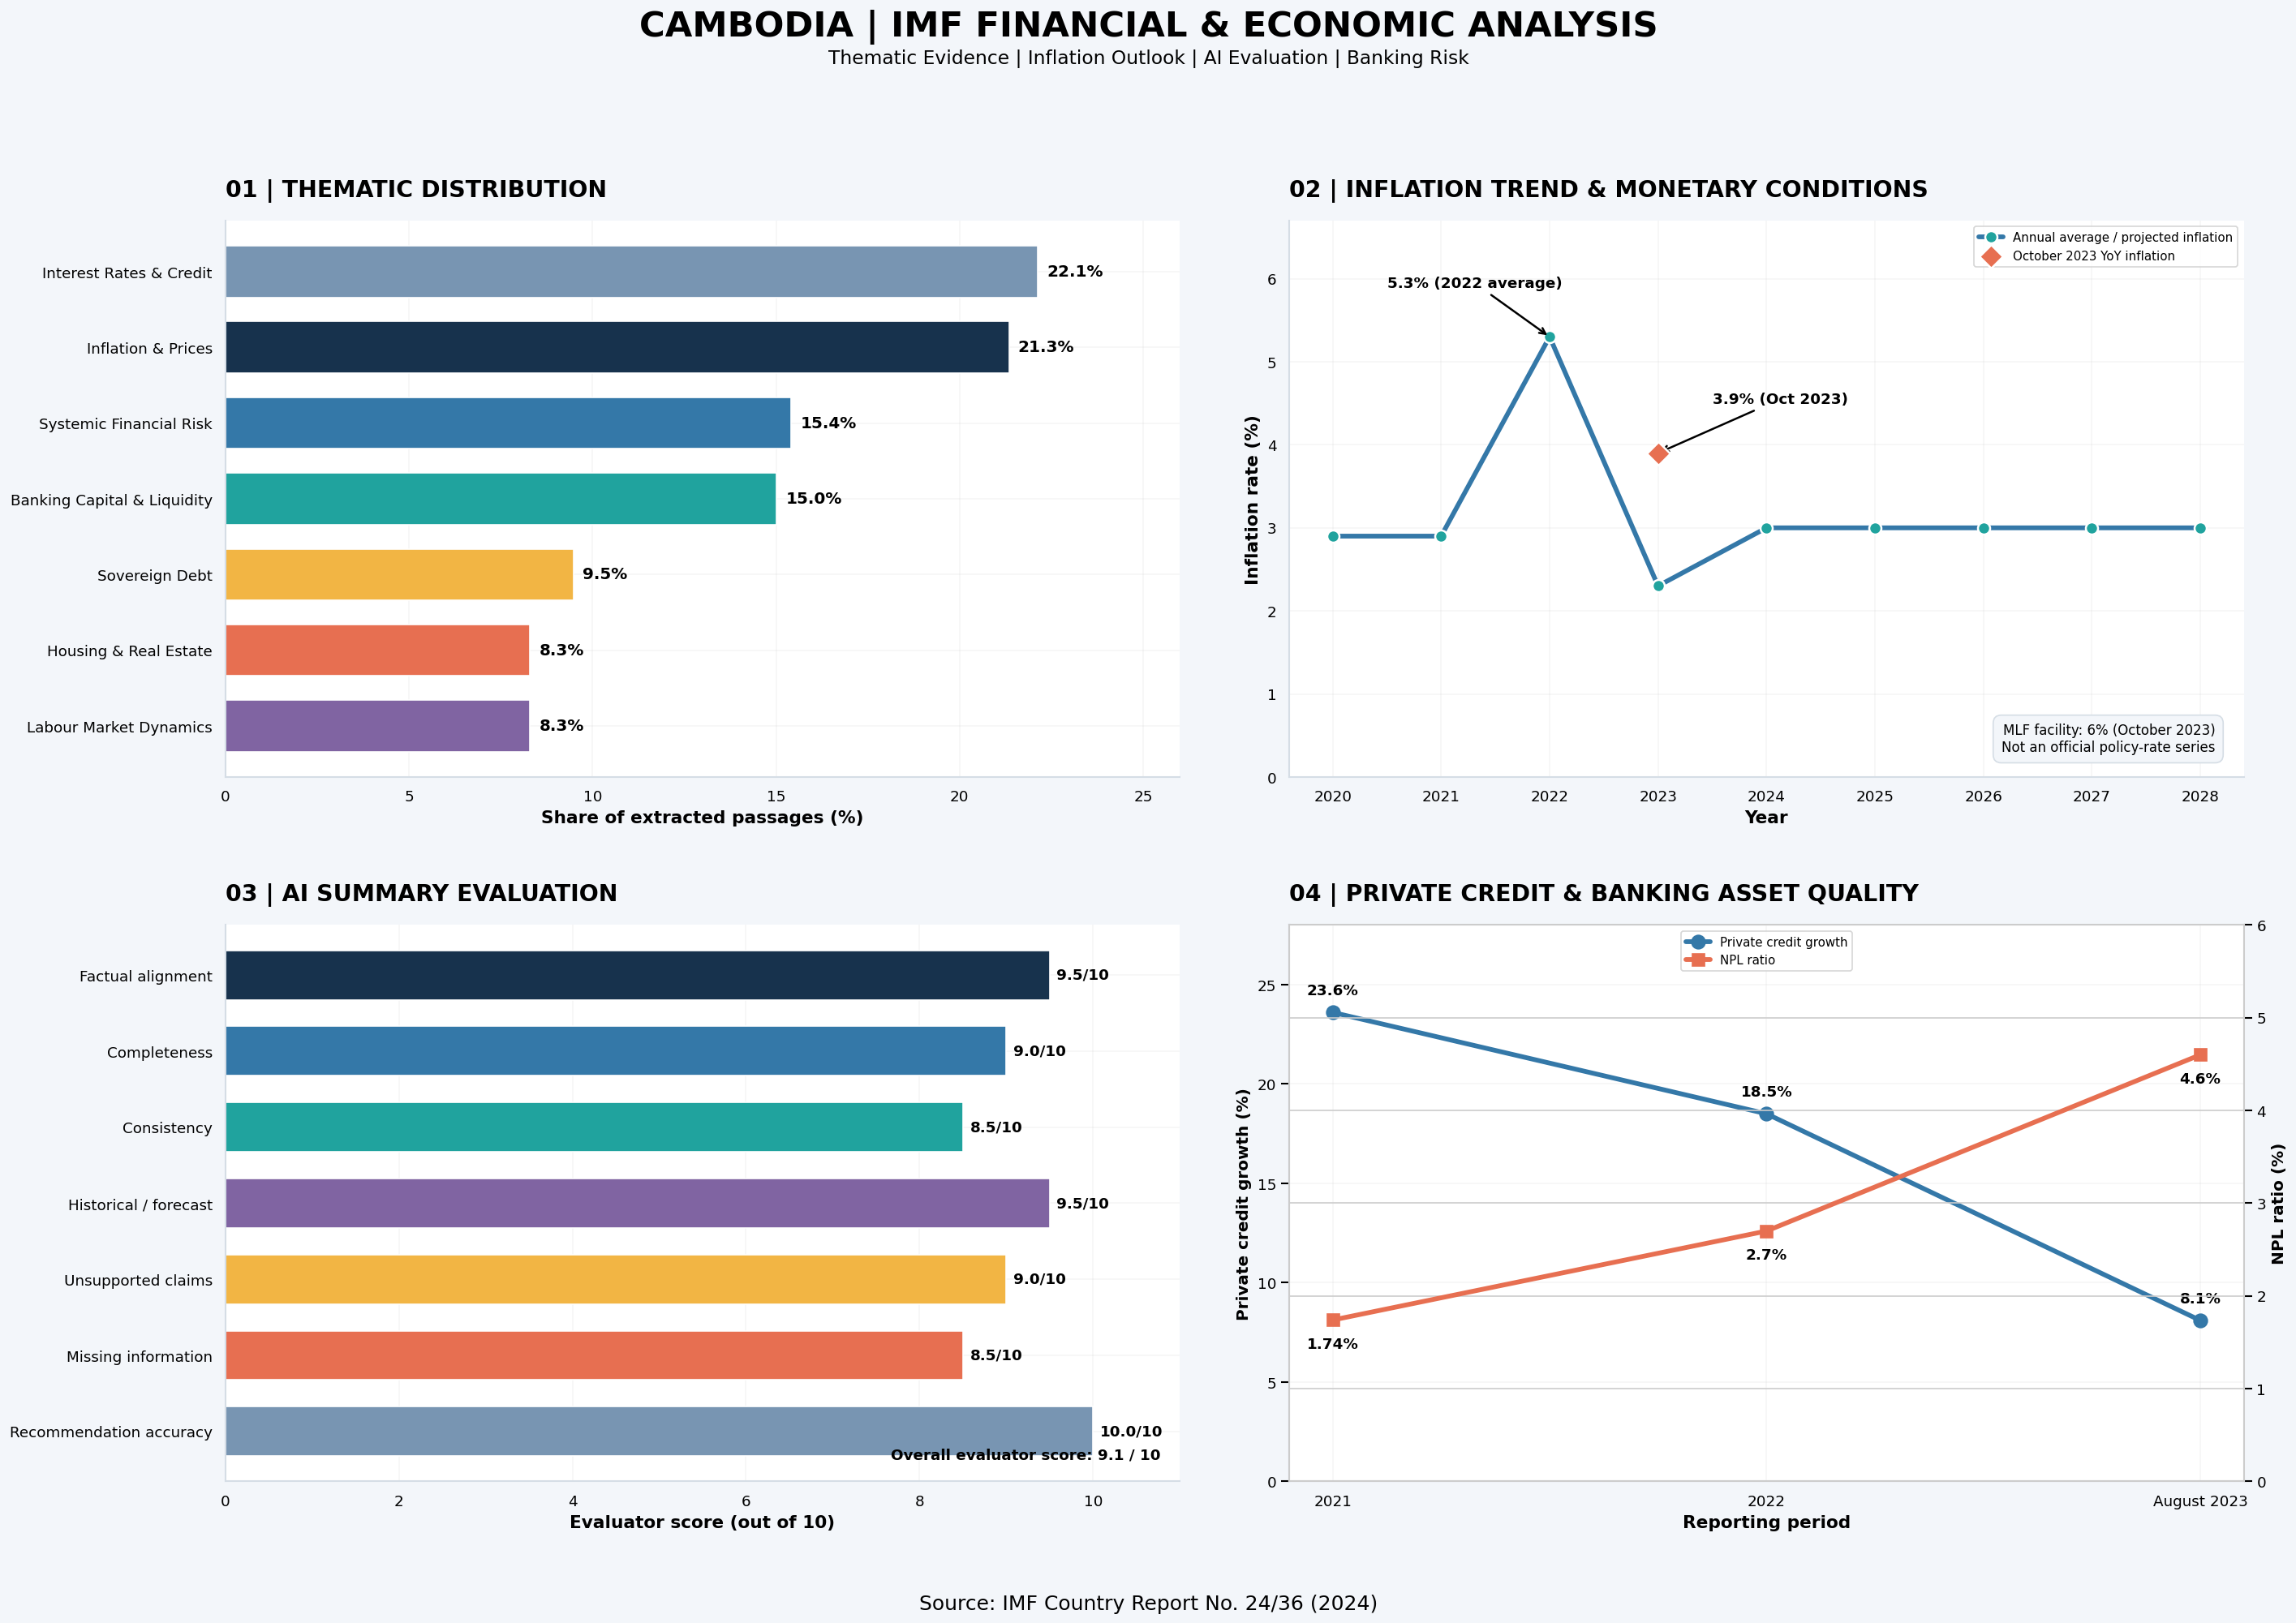

Dashboard created successfully.
600-DPI PNG saved.
Vector PDF saved.
Scalable SVG saved.


In [60]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid", font="DejaVu Sans")

black = "#000000"
navy = "#17324D"
blue = "#3478A8"
teal = "#20A39E"
gold = "#F2B544"
coral = "#E76F51"
purple = "#8064A2"
grey = "#64748B"
light = "#F3F6FA"

plt.rcParams.update({
    "font.size": 12,
    "text.color": black,
    "axes.titlecolor": black,
    "axes.labelcolor": black,
    "xtick.color": black,
    "ytick.color": black,
    "legend.labelcolor": black,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "figure.titlesize": 25,
    "savefig.facecolor": light
})

fig, axes = plt.subplots(2, 2, figsize=(25, 17))
fig.patch.set_facecolor(light)

for ax in axes.flat:
    ax.set_facecolor("white")
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D5DDE5")
    ax.spines["bottom"].set_color("#D5DDE5")
    ax.tick_params(axis="both", colors=black)

fig.suptitle(
    "CAMBODIA | IMF FINANCIAL & ECONOMIC ANALYSIS",
    fontsize=26,
    fontweight="bold",
    color=black,
    y=0.985
)

fig.text(
    0.5, 0.952,
    "Thematic Evidence | Inflation Outlook | AI Evaluation | Banking Risk",
    ha="center",
    fontsize=14,
    color=black
)


themes = [
    "Interest Rates & Credit",
    "Inflation & Prices",
    "Systemic Financial Risk",
    "Banking Capital & Liquidity",
    "Sovereign Debt",
    "Housing & Real Estate",
    "Labour Market Dynamics"
]

theme_counts = [56, 54, 39, 38, 24, 21, 21]

theme_df = pd.DataFrame({
    "Theme": themes,
    "Passages": theme_counts
})

theme_df["Share"] = (
    theme_df["Passages"] /
    theme_df["Passages"].sum() * 100
)

theme_long = pd.melt(
    theme_df,
    id_vars=["Theme"],
    value_vars=["Share"],
    var_name="Measure",
    value_name="Percentage"
)

theme_long = theme_long.sort_values("Percentage")

ax = axes[0, 0]

bar_colours = [
    purple, coral, gold, teal, blue, navy, "#7895B2"
]

bars = ax.barh(
    theme_long["Theme"],
    theme_long["Percentage"],
    color=bar_colours,
    height=0.68
)

for bar, value in zip(bars, theme_long["Percentage"]):
    ax.text(
        value + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=black
    )

ax.set_title(
    "01 | THEMATIC DISTRIBUTION",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color=black,
    pad=18
)

ax.set_xlabel(
    "Share of extracted passages (%)",
    fontsize=13,
    fontweight="bold",
    color=black
)

ax.set_ylabel("", color=black)
ax.set_xlim(0, 26)
ax.tick_params(axis="y", labelsize=11, colors=black)


years = [
    2020, 2021, 2022, 2023,
    2024, 2025, 2026, 2027, 2028
]

inflation = [
    2.9, 2.9, 5.3, 2.3,
    3.0, 3.0, 3.0, 3.0, 3.0
]

ax = axes[0, 1]

ax.plot(
    years,
    inflation,
    color=blue,
    linewidth=3.5,
    marker="o",
    markersize=9,
    markerfacecolor=teal,
    markeredgecolor="white",
    markeredgewidth=1.5,
    label="Annual average / projected inflation"
)

ax.scatter(
    [2023],
    [3.9],
    color=coral,
    s=150,
    marker="D",
    edgecolor="white",
    linewidth=1.5,
    label="October 2023 YoY inflation",
    zorder=5
)

ax.annotate(
    "5.3% (2022 average)",
    xy=(2022, 5.3),
    xytext=(2020.5, 5.9),
    fontsize=11,
    fontweight="bold",
    color=black,
    arrowprops=dict(
        arrowstyle="->",
        color=black,
        linewidth=1.5
    )
)

ax.annotate(
    "3.9% (Oct 2023)",
    xy=(2023, 3.9),
    xytext=(2023.5, 4.5),
    fontsize=11,
    fontweight="bold",
    color=black,
    arrowprops=dict(
        arrowstyle="->",
        color=black,
        linewidth=1.5
    )
)

ax.text(
    0.97,
    0.04,
    "MLF facility: 6% (October 2023)\nNot an official policy-rate series",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    color=black,
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor=light,
        edgecolor="#D5DDE5"
    )
)

ax.set_title(
    "02 | INFLATION TREND & MONETARY CONDITIONS",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color=black,
    pad=18
)

ax.set_xlabel("Year", fontsize=13, fontweight="bold", color=black)
ax.set_ylabel("Inflation rate (%)", fontsize=13, fontweight="bold", color=black)
ax.set_xticks(years)
ax.set_ylim(0, 6.7)
ax.tick_params(axis="both", colors=black)

ax.legend(
    loc="upper right",
    fontsize=9,
    frameon=True,
    facecolor="white",
    labelcolor=black
)


evaluation = {
    "Factual alignment": 9.5,
    "Completeness": 9.0,
    "Consistency": 8.5,
    "Historical / forecast": 9.5,
    "Unsupported claims": 9.0,
    "Missing information": 8.5,
    "Recommendation accuracy": 10.0
}

ax = axes[1, 0]

labels = list(evaluation.keys())
scores = list(evaluation.values())

eval_colours = [
    navy, blue, teal, purple,
    gold, coral, "#7895B2"
]

bars = ax.barh(
    labels[::-1],
    scores[::-1],
    color=eval_colours[::-1],
    height=0.65
)

for bar, value in zip(bars, scores[::-1]):
    ax.text(
        value + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}/10",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=black
    )

ax.set_xlim(0, 11)

ax.set_xlabel(
    "Evaluator score (out of 10)",
    fontsize=13,
    fontweight="bold",
    color=black
)

ax.set_ylabel("", color=black)

ax.set_title(
    "03 | AI SUMMARY EVALUATION",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color=black,
    pad=18
)

ax.tick_params(axis="both", colors=black)

ax.text(
    0.98,
    0.04,
    "Overall evaluator score: 9.1 / 10",
    transform=ax.transAxes,
    ha="right",
    fontsize=11,
    fontweight="bold",
    color=black
)


periods = [
    "2021",
    "2022",
    "August 2023"
]

credit_growth = [23.6, 18.5, 8.1]
npl_ratio = [1.74, 2.7, 4.6]

bank_df = pd.DataFrame({
    "Period": periods,
    "Private credit growth": credit_growth,
    "NPL ratio": npl_ratio
})

bank_long = pd.melt(
    bank_df,
    id_vars=["Period"],
    value_vars=[
        "Private credit growth",
        "NPL ratio"
    ],
    var_name="Indicator",
    value_name="Percentage"
)

ax = axes[1, 1]
ax2 = ax.twinx()

line1 = ax.plot(
    periods,
    credit_growth,
    color=blue,
    linewidth=3.5,
    marker="o",
    markersize=10,
    label="Private credit growth"
)

line2 = ax2.plot(
    periods,
    npl_ratio,
    color=coral,
    linewidth=3.5,
    marker="s",
    markersize=9,
    label="NPL ratio"
)

for x, value in enumerate(credit_growth):
    ax.annotate(
        f"{value:.1f}%",
        (x, value),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color=black
    )

for x, value in enumerate(npl_ratio):
    ax2.annotate(
        f"{value:.2f}%" if x == 0 else f"{value:.1f}%",
        (x, value),
        xytext=(0, -21),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color=black
    )

ax.set_title(
    "04 | PRIVATE CREDIT & BANKING ASSET QUALITY",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color=black,
    pad=18
)

ax.set_xlabel(
    "Reporting period",
    fontsize=13,
    fontweight="bold",
    color=black
)

ax.set_ylabel(
    "Private credit growth (%)",
    fontsize=12,
    fontweight="bold",
    color=black
)

ax2.set_ylabel(
    "NPL ratio (%)",
    fontsize=12,
    fontweight="bold",
    color=black
)

ax.tick_params(axis="both", colors=black)
ax2.tick_params(axis="y", colors=black)

ax.set_ylim(0, 28)
ax2.set_ylim(0, 6)

ax.legend(
    line1 + line2,
    ["Private credit growth", "NPL ratio"],
    loc="upper center",
    fontsize=9,
    frameon=True,
    labelcolor=black
)


fig.text(
    0.5,
    0.018,
    "Source: IMF Country Report No. 24/36 (2024)",
    ha="center",
    fontsize=15,
    color=black
)

plt.tight_layout(
    rect=[0.025, 0.055, 0.975, 0.925],
    h_pad=3.5,
    w_pad=3.5
)


fig.savefig(
    "Cambodia_Professional_Dashboard_600DPI.png",
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

fig.savefig(
    "Cambodia_Professional_Dashboard.pdf",
    format="pdf",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

fig.savefig(
    "Cambodia_Professional_Dashboard.svg",
    format="svg",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Dashboard created successfully.")
print("600-DPI PNG saved.")
print("Vector PDF saved.")
print("Scalable SVG saved.")


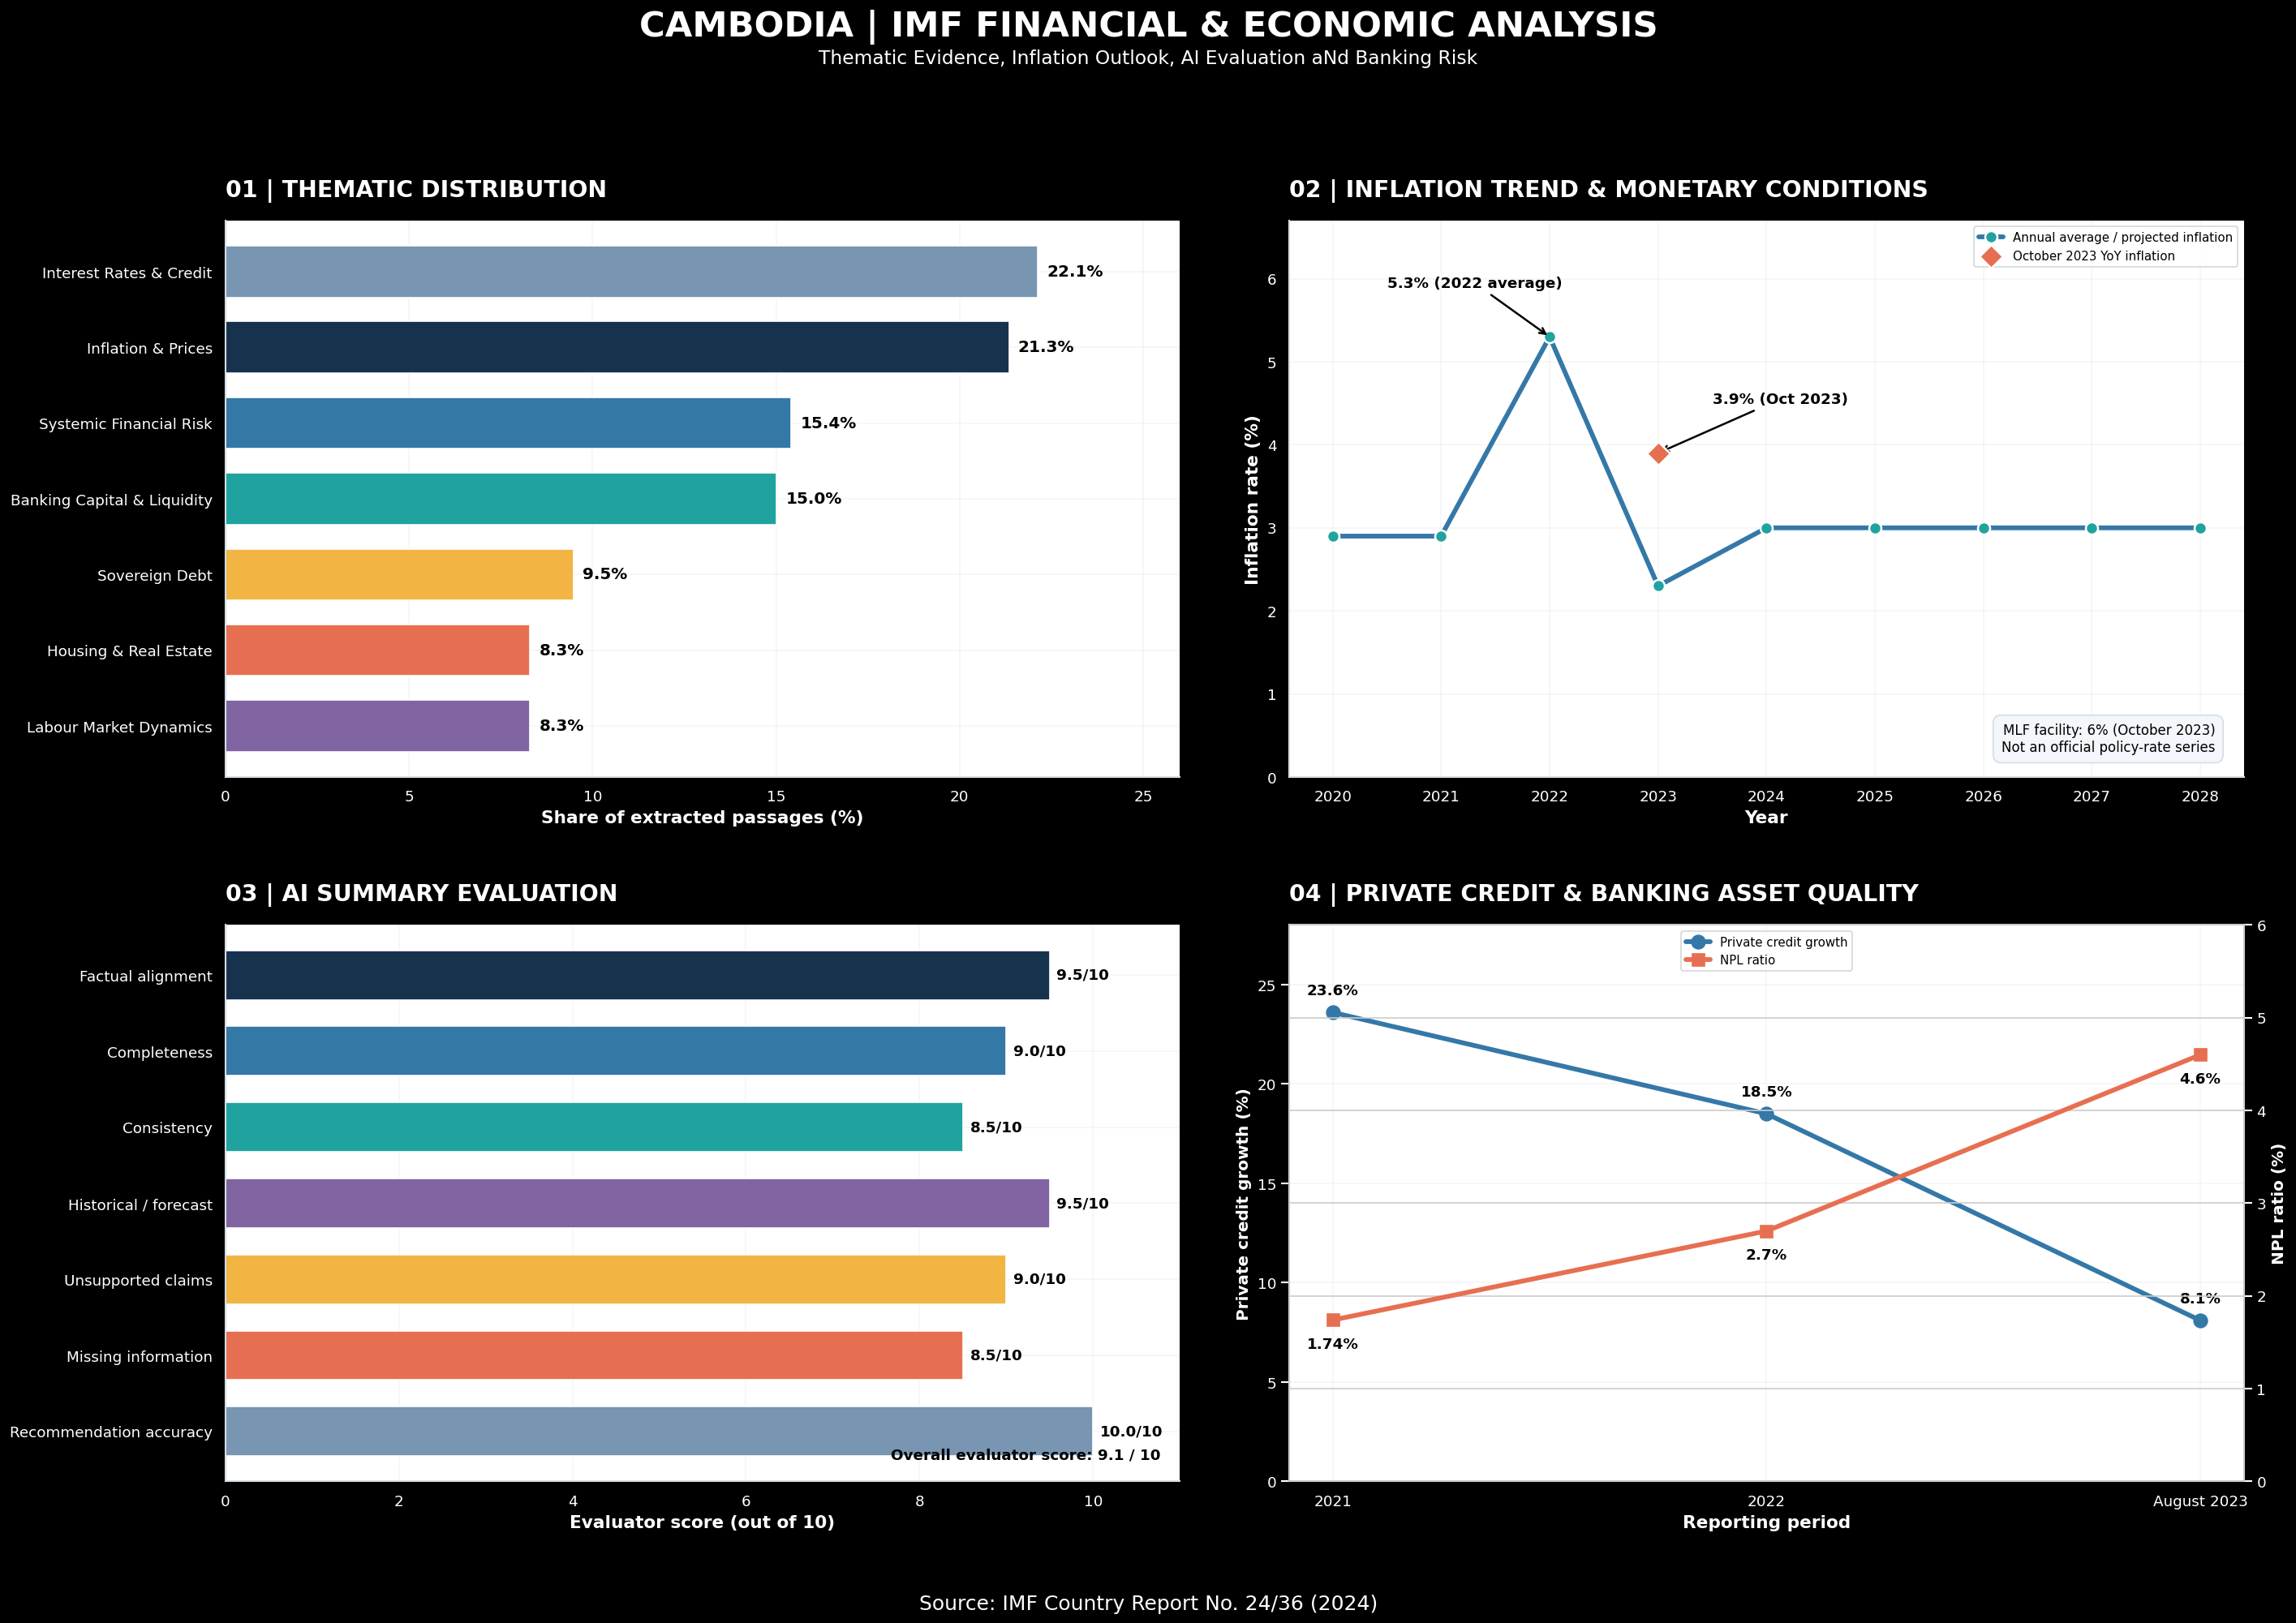

Dark dashboard created successfully.
600-DPI PNG saved.
Vector PDF saved.
Scalable SVG saved.


In [59]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid", font="DejaVu Sans")

black = "#000000"
white = "#FFFFFF"
navy = "#17324D"
blue = "#3478A8"
teal = "#20A39E"
gold = "#F2B544"
coral = "#E76F51"
purple = "#8064A2"
grey = "#64748B"

plt.rcParams.update({
    "font.size": 12,
    "text.color": white,
    "axes.titlecolor": white,
    "axes.labelcolor": white,
    "xtick.color": white,
    "ytick.color": white,
    "legend.labelcolor": white,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "figure.titlesize": 25,
    "savefig.facecolor": black
})

fig, axes = plt.subplots(2, 2, figsize=(25, 17))
fig.patch.set_facecolor(black)

for ax in axes.flat:
    ax.set_facecolor("white")
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D5DDE5")
    ax.spines["bottom"].set_color("#D5DDE5")
    ax.tick_params(axis="both", colors=white)

fig.suptitle(
    "CAMBODIA | IMF FINANCIAL & ECONOMIC ANALYSIS",
    fontsize=26,
    fontweight="bold",
    color=white,
    y=0.985
)

fig.text(
    0.5, 0.952,
    "Thematic Evidence, Inflation Outlook, AI Evaluation aNd Banking Risk",
    ha="center",
    fontsize=14,
    color=white
)


themes = [
    "Interest Rates & Credit",
    "Inflation & Prices",
    "Systemic Financial Risk",
    "Banking Capital & Liquidity",
    "Sovereign Debt",
    "Housing & Real Estate",
    "Labour Market Dynamics"
]

theme_counts = [56, 54, 39, 38, 24, 21, 21]

theme_df = pd.DataFrame({
    "Theme": themes,
    "Passages": theme_counts
})

theme_df["Share"] = (
    theme_df["Passages"] /
    theme_df["Passages"].sum() * 100
)

theme_long = pd.melt(
    theme_df,
    id_vars=["Theme"],
    value_vars=["Share"],
    var_name="Measure",
    value_name="Percentage"
)

theme_long = theme_long.sort_values("Percentage")

ax = axes[0, 0]

bar_colours = [
    purple, coral, gold, teal, blue, navy, "#7895B2"
]

bars = ax.barh(
    theme_long["Theme"],
    theme_long["Percentage"],
    color=bar_colours,
    height=0.68
)

for bar, value in zip(bars, theme_long["Percentage"]):
    ax.text(
        value + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=black
    )

ax.set_title(
    "01 | THEMATIC DISTRIBUTION",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color=white,
    pad=18
)

ax.set_xlabel(
    "Share of extracted passages (%)",
    fontsize=13,
    fontweight="bold",
    color=white
)

ax.set_ylabel("", color=white)
ax.set_xlim(0, 26)
ax.tick_params(axis="both", colors=white)


years = [
    2020, 2021, 2022, 2023,
    2024, 2025, 2026, 2027, 2028
]

inflation = [
    2.9, 2.9, 5.3, 2.3,
    3.0, 3.0, 3.0, 3.0, 3.0
]

ax = axes[0, 1]

ax.plot(
    years,
    inflation,
    color=blue,
    linewidth=3.5,
    marker="o",
    markersize=9,
    markerfacecolor=teal,
    markeredgecolor="white",
    markeredgewidth=1.5,
    label="Annual average / projected inflation"
)

ax.scatter(
    [2023],
    [3.9],
    color=coral,
    s=150,
    marker="D",
    edgecolor="white",
    linewidth=1.5,
    label="October 2023 YoY inflation",
    zorder=5
)

ax.annotate(
    "5.3% (2022 average)",
    xy=(2022, 5.3),
    xytext=(2020.5, 5.9),
    fontsize=11,
    fontweight="bold",
    color=black,
    arrowprops=dict(
        arrowstyle="->",
        color=black,
        linewidth=1.5
    )
)

ax.annotate(
    "3.9% (Oct 2023)",
    xy=(2023, 3.9),
    xytext=(2023.5, 4.5),
    fontsize=11,
    fontweight="bold",
    color=black,
    arrowprops=dict(
        arrowstyle="->",
        color=black,
        linewidth=1.5
    )
)

ax.text(
    0.97,
    0.04,
    "MLF facility: 6% (October 2023)\nNot an official policy-rate series",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    color=black,
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#F3F6FA",
        edgecolor="#D5DDE5"
    )
)

ax.set_title(
    "02 | INFLATION TREND & MONETARY CONDITIONS",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color=white,
    pad=18
)

ax.set_xlabel("Year", fontsize=13, fontweight="bold", color=white)
ax.set_ylabel("Inflation rate (%)", fontsize=13, fontweight="bold", color=white)
ax.set_xticks(years)
ax.set_ylim(0, 6.7)
ax.tick_params(axis="both", colors=white)

ax.legend(
    loc="upper right",
    fontsize=9,
    frameon=True,
    facecolor="white",
    labelcolor=black
)


evaluation = {
    "Factual alignment": 9.5,
    "Completeness": 9.0,
    "Consistency": 8.5,
    "Historical / forecast": 9.5,
    "Unsupported claims": 9.0,
    "Missing information": 8.5,
    "Recommendation accuracy": 10.0
}

ax = axes[1, 0]

labels = list(evaluation.keys())
scores = list(evaluation.values())

eval_colours = [
    navy, blue, teal, purple,
    gold, coral, "#7895B2"
]

bars = ax.barh(
    labels[::-1],
    scores[::-1],
    color=eval_colours[::-1],
    height=0.65
)

for bar, value in zip(bars, scores[::-1]):
    ax.text(
        value + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}/10",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=black
    )

ax.set_xlim(0, 11)

ax.set_xlabel(
    "Evaluator score (out of 10)",
    fontsize=13,
    fontweight="bold",
    color=white
)

ax.set_ylabel("", color=white)

ax.set_title(
    "03 | AI SUMMARY EVALUATION",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color=white,
    pad=18
)

ax.tick_params(axis="both", colors=white)

ax.text(
    0.98,
    0.04,
    "Overall evaluator score: 9.1 / 10",
    transform=ax.transAxes,
    ha="right",
    fontsize=11,
    fontweight="bold",
    color=black
)


periods = [
    "2021",
    "2022",
    "August 2023"
]

credit_growth = [23.6, 18.5, 8.1]
npl_ratio = [1.74, 2.7, 4.6]

bank_df = pd.DataFrame({
    "Period": periods,
    "Private credit growth": credit_growth,
    "NPL ratio": npl_ratio
})

bank_long = pd.melt(
    bank_df,
    id_vars=["Period"],
    value_vars=[
        "Private credit growth",
        "NPL ratio"
    ],
    var_name="Indicator",
    value_name="Percentage"
)

ax = axes[1, 1]
ax2 = ax.twinx()
ax2.set_facecolor("none")

line1 = ax.plot(
    periods,
    credit_growth,
    color=blue,
    linewidth=3.5,
    marker="o",
    markersize=10,
    label="Private credit growth"
)

line2 = ax2.plot(
    periods,
    npl_ratio,
    color=coral,
    linewidth=3.5,
    marker="s",
    markersize=9,
    label="NPL ratio"
)

for x, value in enumerate(credit_growth):
    ax.annotate(
        f"{value:.1f}%",
        (x, value),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color=black
    )

for x, value in enumerate(npl_ratio):
    ax2.annotate(
        f"{value:.2f}%" if x == 0 else f"{value:.1f}%",
        (x, value),
        xytext=(0, -21),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color=black
    )

ax.set_title(
    "04 | PRIVATE CREDIT & BANKING ASSET QUALITY",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color=white,
    pad=18
)

ax.set_xlabel(
    "Reporting period",
    fontsize=13,
    fontweight="bold",
    color=white
)

ax.set_ylabel(
    "Private credit growth (%)",
    fontsize=12,
    fontweight="bold",
    color=white
)

ax2.set_ylabel(
    "NPL ratio (%)",
    fontsize=12,
    fontweight="bold",
    color=white
)

ax.tick_params(axis="both", colors=white)
ax2.tick_params(axis="y", colors=white)

ax.set_ylim(0, 28)
ax2.set_ylim(0, 6)

ax.legend(
    line1 + line2,
    ["Private credit growth", "NPL ratio"],
    loc="upper center",
    fontsize=9,
    frameon=True,
    facecolor="white",
    labelcolor=black
)


fig.text(
    0.5,
    0.018,
    "Source: IMF Country Report No. 24/36 (2024)",
    ha="center",
    fontsize=15,
    color=white
)

plt.tight_layout(
    rect=[0.025, 0.055, 0.975, 0.925],
    h_pad=3.5,
    w_pad=3.5
)

fig.savefig(
    "Cambodia_Professional_Dashboard_600DPI.png",
    dpi=600,
    bbox_inches="tight",
    facecolor=black
)

fig.savefig(
    "Cambodia_Professional_Dashboard.pdf",
    format="pdf",
    bbox_inches="tight",
    facecolor=black
)

fig.savefig(
    "Cambodia_Professional_Dashboard.svg",
    format="svg",
    bbox_inches="tight",
    facecolor=black
)

plt.show()

print("Dark dashboard created successfully.")
print("600-DPI PNG saved.")
print("Vector PDF saved.")
print("Scalable SVG saved.")


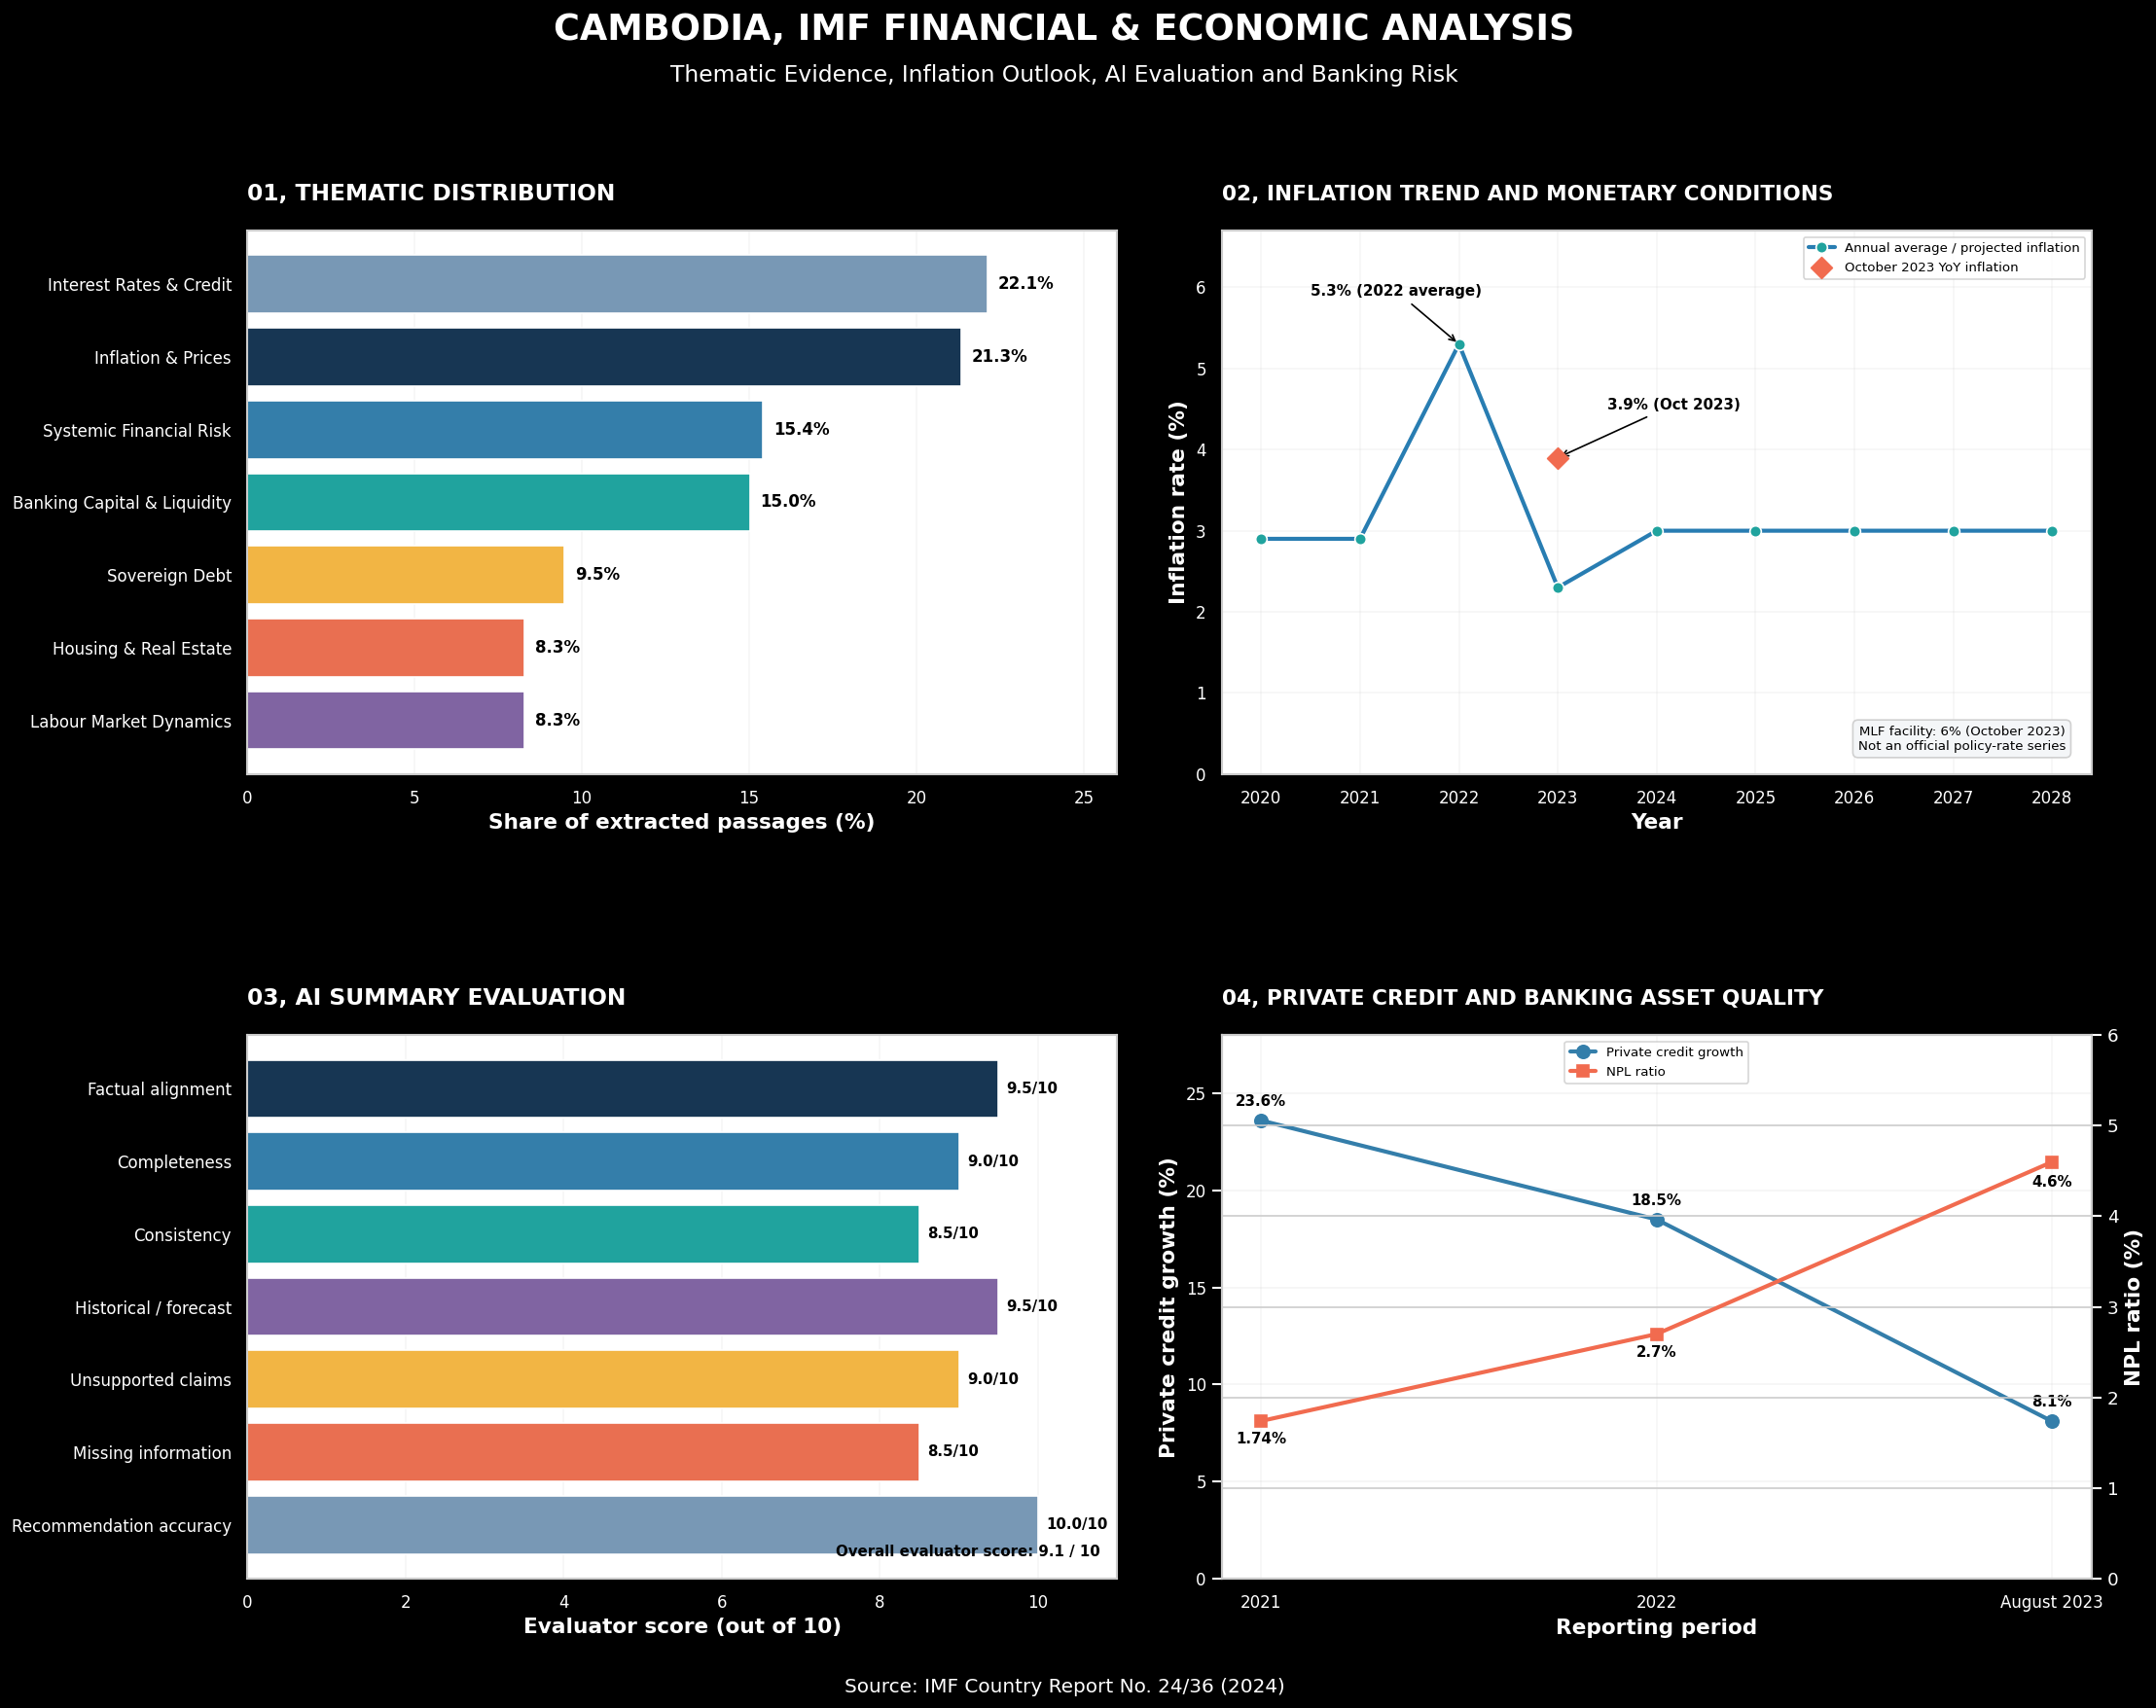

In [73]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "DejaVu Sans"

theme_data = {
    "Theme": [
        "Interest Rates & Credit",
        "Inflation & Prices",
        "Systemic Financial Risk",
        "Banking Capital & Liquidity",
        "Sovereign Debt",
        "Housing & Real Estate",
        "Labour Market Dynamics"
    ],
    "Share": [22.13, 21.34, 15.42, 15.02, 9.49, 8.30, 8.30]
}

theme_df = pd.DataFrame(theme_data)

inflation_data = {
    "Year": [2020, 2021, 2022, 2023, 2024, 2025, 2026, 2027, 2028],
    "Inflation": [2.9, 2.9, 5.3, 2.3, 3.0, 3.0, 3.0, 3.0, 3.0]
}

inflation_df = pd.DataFrame(inflation_data)

evaluation_data = {
    "Criteria": [
        "Factual alignment",
        "Completeness",
        "Consistency",
        "Historical / forecast",
        "Unsupported claims",
        "Missing information",
        "Recommendation accuracy"
    ],
    "Score": [9.5, 9.0, 8.5, 9.5, 9.0, 8.5, 10.0]
}

evaluation_df = pd.DataFrame(evaluation_data)

credit_data = {
    "Period": ["2021", "2022", "August 2023"],
    "Credit Growth": [23.6, 18.5, 8.1],
    "NPL Ratio": [1.74, 2.7, 4.6]
}

credit_df = pd.DataFrame(credit_data)

fig, axes = plt.subplots(2, 2, figsize=(20, 15))

fig.patch.set_facecolor("black")

for ax in axes.flat:
    ax.set_facecolor("white")
    ax.tick_params(axis="both", colors="white", labelsize=10)
    ax.xaxis.label.set_color("white")
    ax.yaxis.label.set_color("white")
    ax.grid(True, alpha=0.18)
    ax.set_axisbelow(True)

fig.suptitle(
    "CAMBODIA, IMF FINANCIAL & ECONOMIC ANALYSIS",
    fontsize=22,
    fontweight="bold",
    color="white",
    y=0.985
)

fig.text(
    0.5, 0.945,
    "Thematic Evidence, Inflation Outlook, AI Evaluation and Banking Risk",
    ha="center",
    fontsize=14,
    color="white"
)

fig.text(
    0.5, 0.025,
    "Source: IMF Country Report No. 24/36 (2024)",
    ha="center",
    fontsize=12,
    color="white"
)

ax1 = axes[0, 0]

theme_colors = [
    "#7898B5",
    "#173653",
    "#347EAA",
    "#20A39E",
    "#F2B544",
    "#E96F51",
    "#8064A2"
]

bars = ax1.barh(
    theme_df["Theme"],
    theme_df["Share"],
    color=theme_colors
)

ax1.invert_yaxis()

ax1.set_title(
    "01, THEMATIC DISTRIBUTION",
    loc="left",
    fontsize=14,
    fontweight="bold",
    color="white",
    pad=12,
    y=1.02
)

ax1.set_xlabel(
    "Share of extracted passages (%)",
    fontweight="bold",
    color="white"
)

ax1.set_xlim(0, 26)

for bar, value in zip(bars, theme_df["Share"]):
    ax1.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="black"
    )

ax1.grid(axis="x", alpha=0.18)
ax1.grid(axis="y", visible=False)

ax2 = axes[0, 1]

ax2.plot(
    inflation_df["Year"],
    inflation_df["Inflation"],
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="#287DB2",
    markerfacecolor="#20A39E",
    markeredgecolor="white",
    label="Annual average / projected inflation"
)

ax2.scatter(
    [2023],
    [3.9],
    marker="D",
    s=85,
    color="#F16B4F",
    label="October 2023 YoY inflation",
    zorder=5
)

ax2.annotate(
    "5.3% (2022 average)",
    xy=(2022, 5.3),
    xytext=(2020.5, 5.9),
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=9,
    fontweight="bold",
    color="black"
)

ax2.annotate(
    "3.9% (Oct 2023)",
    xy=(2023, 3.9),
    xytext=(2023.5, 4.5),
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=9,
    fontweight="bold",
    color="black"
)

ax2.text(
    0.97, 0.04,
    "MLF facility: 6% (October 2023)\nNot an official policy-rate series",
    transform=ax2.transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
    color="black",
    bbox=dict(
        facecolor="#F4F6F8",
        edgecolor="#D0D0D0",
        boxstyle="round,pad=0.4"
    )
)

ax2.set_title(
    "02, INFLATION TREND AND MONETARY CONDITIONS",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color="white",
    pad=12,
    y=1.02
)

ax2.set_xlabel("Year", fontweight="bold", color="white")
ax2.set_ylabel("Inflation rate (%)", fontweight="bold", color="white")
ax2.set_xticks(inflation_df["Year"])
ax2.set_ylim(0, 6.7)
ax2.legend(loc="upper right", fontsize=8, frameon=True)

ax3 = axes[1, 0]

evaluation_colors = [
    "#173653",
    "#347EAA",
    "#20A39E",
    "#8064A2",
    "#F2B544",
    "#E96F51",
    "#7898B5"
]

bars = ax3.barh(
    evaluation_df["Criteria"],
    evaluation_df["Score"],
    color=evaluation_colors
)

ax3.invert_yaxis()

ax3.set_title(
    "03, AI SUMMARY EVALUATION",
    loc="left",
    fontsize=14,
    fontweight="bold",
    color="white",
    pad=12,
    y=1.02
)

ax3.set_xlabel(
    "Evaluator score (out of 10)",
    fontweight="bold",
    color="white"
)

ax3.set_xlim(0, 11)

for bar, value in zip(bars, evaluation_df["Score"]):
    ax3.text(
        value + 0.1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}/10",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="black"
    )

ax3.text(
    0.98, 0.035,
    "Overall evaluator score: 9.1 / 10",
    transform=ax3.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    color="black"
)

ax3.grid(axis="x", alpha=0.18)
ax3.grid(axis="y", visible=False)

ax4 = axes[1, 1]

x = np.arange(len(credit_df))

line1 = ax4.plot(
    x,
    credit_df["Credit Growth"],
    marker="o",
    linewidth=2.5,
    markersize=8,
    color="#347EAA",
    label="Private credit growth"
)

ax4.set_ylabel(
    "Private credit growth (%)",
    color="white",
    fontweight="bold"
)

ax4.set_xticks(x)
ax4.set_xticklabels(credit_df["Period"], color="white")
ax4.set_xlabel(
    "Reporting period",
    fontweight="bold",
    color="white"
)

ax4.set_ylim(0, 28)

ax4b = ax4.twinx()
ax4b.set_facecolor("none")

ax4b.tick_params(axis="y", colors="white")
ax4b.yaxis.label.set_color("white")

line2 = ax4b.plot(
    x,
    credit_df["NPL Ratio"],
    marker="s",
    linewidth=2.5,
    markersize=7,
    color="#F16B4F",
    label="NPL ratio"
)

ax4b.set_ylabel(
    "NPL ratio (%)",
    color="white",
    fontweight="bold"
)

ax4b.set_ylim(0, 6)

ax4.set_title(
    "04, PRIVATE CREDIT AND BANKING ASSET QUALITY",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color="white",
    pad=12,
    y=1.02
)

for i, value in enumerate(credit_df["Credit Growth"]):
    ax4.annotate(
        f"{value:.1f}%",
        (x[i], value),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="black"
    )

for i, value in enumerate(credit_df["NPL Ratio"]):
    offset = -15 if i == 2 else -14

    ax4b.annotate(
        f"{value:.2f}%" if i == 0 else f"{value:.1f}%",
        (x[i], value),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="black"
    )

lines = line1 + line2
labels = [line.get_label() for line in lines]

ax4.legend(
    lines,
    labels,
    loc="upper center",
    fontsize=8,
    frameon=True
)

ax4.grid(axis="y", alpha=0.2)

plt.subplots_adjust(
    left=0.15,
    right=0.94,
    top=0.86,
    bottom=0.09,
    hspace=0.48,
    wspace=0.12
)

plt.savefig(
    "Cambodia_Professional_Dashboard_600DPI.png",
    dpi=600,
    facecolor="black",
    bbox_inches="tight"
)

plt.savefig(
    "Cambodia_Professional_Dashboard.pdf",
    facecolor="black",
    bbox_inches="tight"
)

plt.savefig(
    "Cambodia_Professional_Dashboard.svg",
    facecolor="black",
    bbox_inches="tight"
)

plt.show()


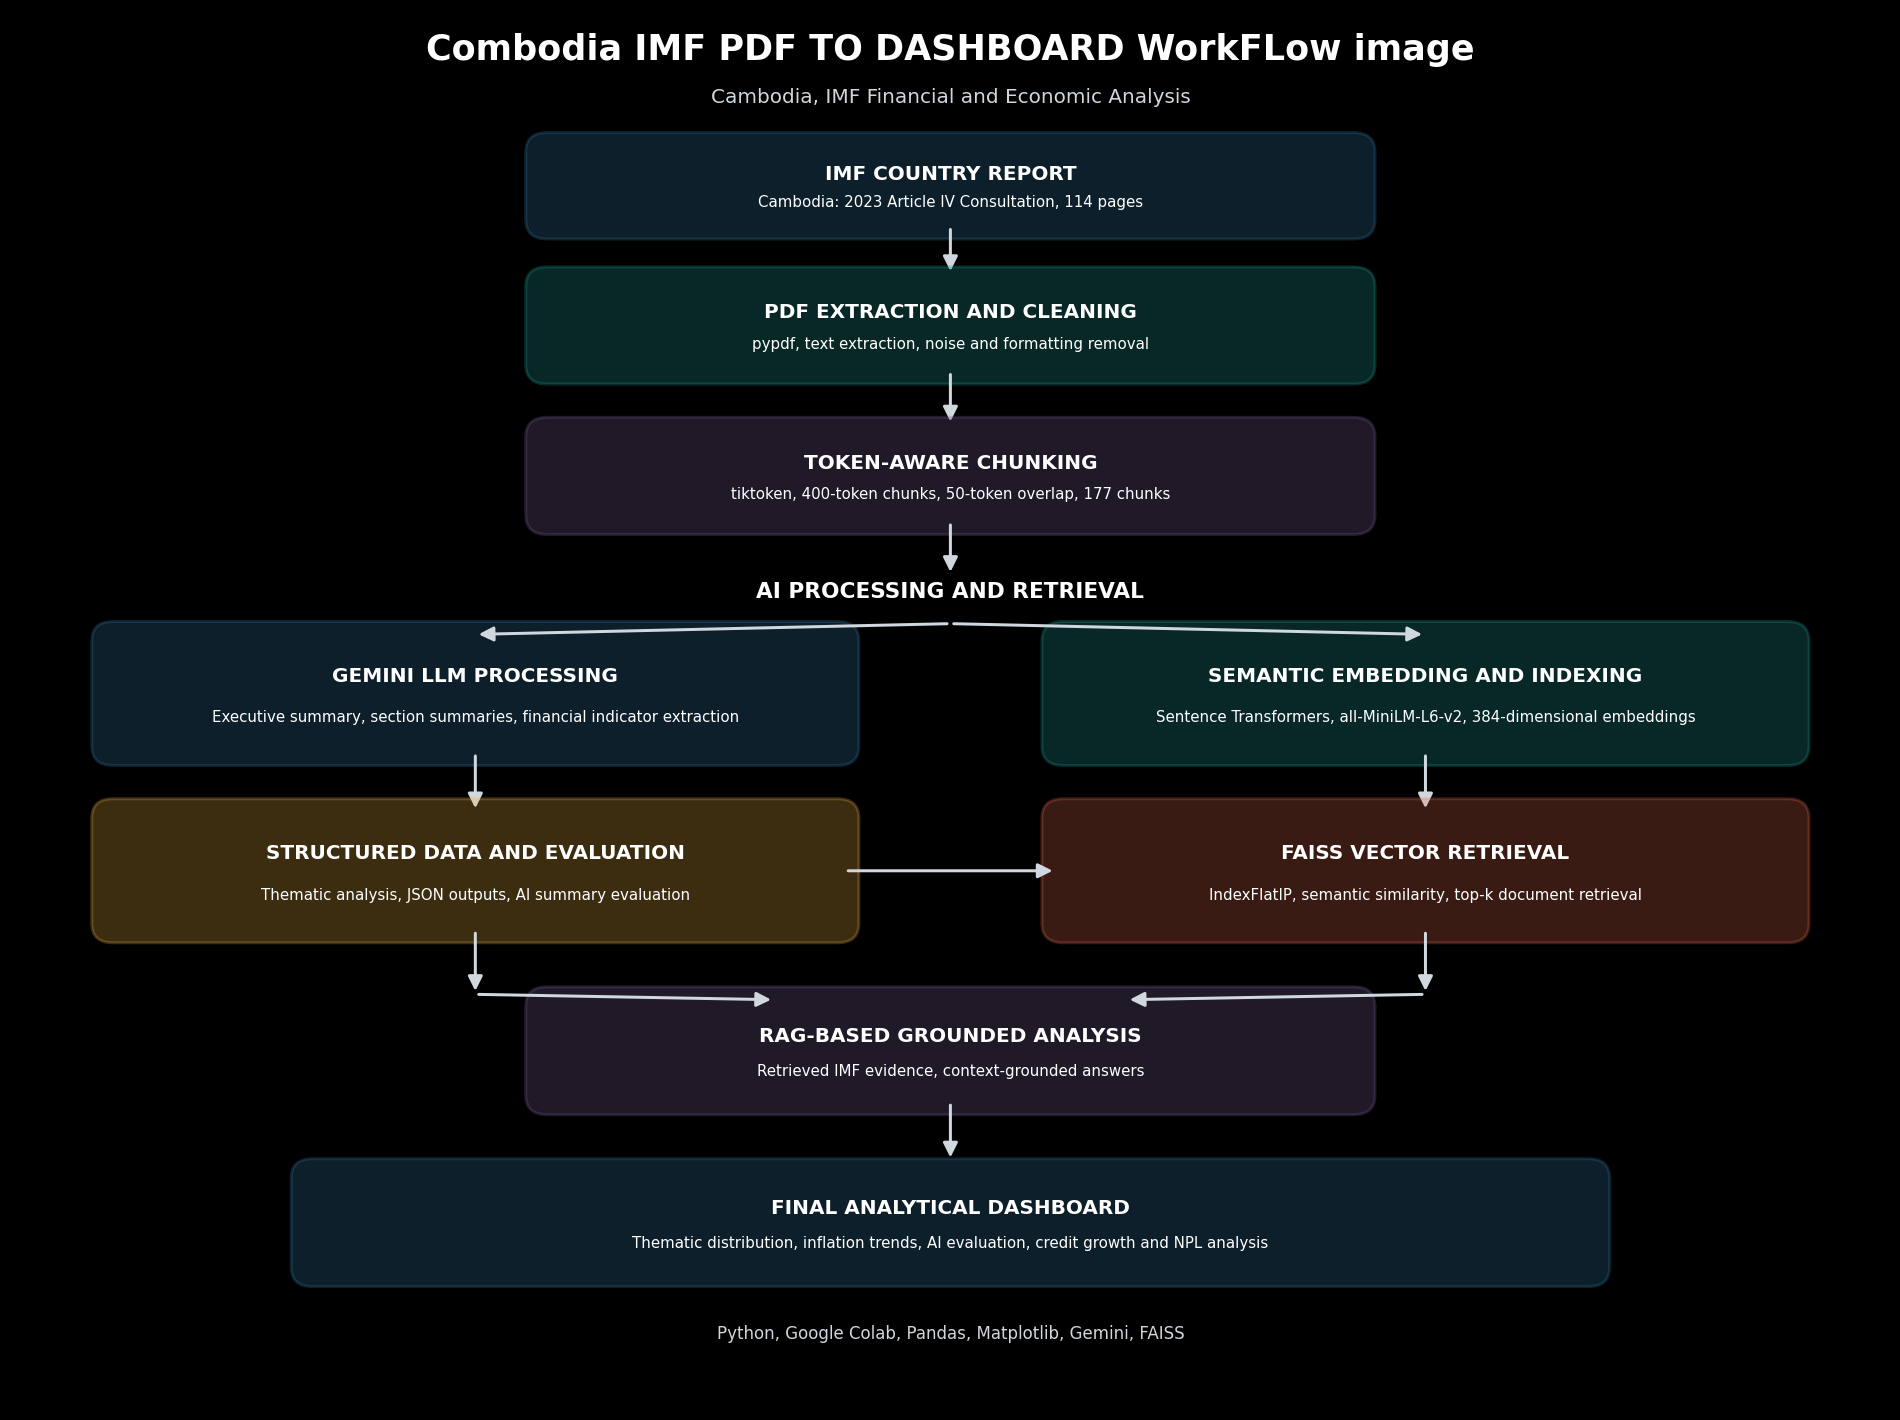

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 12))

fig.patch.set_facecolor("black")
ax.set_facecolor("black")
ax.set_xlim(0, 16)
ax.set_ylim(0, 13)
ax.axis("off")

def add_box(x, y, w, h, title, subtitle, color):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12,rounding_size=0.18",
        linewidth=1.8,
        edgecolor=color,
        facecolor=color,
        alpha=0.25
    )
    ax.add_patch(box)

    ax.text(
        x + w / 2, y + h * 0.65,
        title,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="white"
    )

    ax.text(
        x + w / 2, y + h * 0.30,
        subtitle,
        ha="center",
        va="center",
        fontsize=9,
        color="white",
        wrap=True
    )

def add_arrow(x1, y1, x2, y2):
    arrow = FancyArrowPatch(
        (x1, y1),
        (x2, y2),
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=1.8,
        color="#D0D7DE"
    )
    ax.add_patch(arrow)

ax.text(
    8, 12.55,
    "Combodia IMF PDF TO DASHBOARD WorkFLow image",
    ha="center",
    fontsize=21,
    fontweight="bold",
    color="white"
)

ax.text(
    8, 12.15,
    "Cambodia, IMF Financial and Economic Analysis",
    ha="center",
    fontsize=12,
    color="#D0D7DE"
)

add_box(
    4.5, 11.0, 7, 0.75,
    "IMF COUNTRY REPORT",
    "Cambodia: 2023 Article IV Consultation, 114 pages",
    "#347EAA"
)

add_arrow(8, 11.0, 8, 10.55)

add_box(
    4.5, 9.65, 7, 0.85,
    "PDF EXTRACTION AND CLEANING",
    "pypdf, text extraction, noise and formatting removal",
    "#20A39E"
)

add_arrow(8, 9.65, 8, 9.15)

add_box(
    4.5, 8.25, 7, 0.85,
    "TOKEN-AWARE CHUNKING",
    "tiktoken, 400-token chunks, 50-token overlap, 177 chunks",
    "#8064A2"
)

add_arrow(8, 8.25, 8, 7.75)

ax.text(
    8, 7.55,
    "AI PROCESSING AND RETRIEVAL",
    ha="center",
    fontsize=13,
    fontweight="bold",
    color="white"
)

add_box(
    0.8, 6.1, 6.3, 1.1,
    "GEMINI LLM PROCESSING",
    "Executive summary, section summaries, financial indicator extraction",
    "#347EAA"
)

add_box(
    8.9, 6.1, 6.3, 1.1,
    "SEMANTIC EMBEDDING AND INDEXING",
    "Sentence Transformers, all-MiniLM-L6-v2, 384-dimensional embeddings",
    "#20A39E"
)

add_arrow(8, 7.3, 3.95, 7.2)
add_arrow(8, 7.3, 12.05, 7.2)

add_arrow(3.95, 6.1, 3.95, 5.55)
add_arrow(12.05, 6.1, 12.05, 5.55)

add_box(
    0.8, 4.45, 6.3, 1.1,
    "STRUCTURED DATA AND EVALUATION",
    "Thematic analysis, JSON outputs, AI summary evaluation",
    "#F2B544"
)

add_box(
    8.9, 4.45, 6.3, 1.1,
    "FAISS VECTOR RETRIEVAL",
    "IndexFlatIP, semantic similarity, top-k document retrieval",
    "#E96F51"
)

add_arrow(7.1, 5.0, 8.9, 5.0)

add_arrow(3.95, 4.45, 3.95, 3.85)
add_arrow(12.05, 4.45, 12.05, 3.85)

add_box(
    4.5, 2.85, 7, 0.95,
    "RAG-BASED GROUNDED ANALYSIS",
    "Retrieved IMF evidence, context-grounded answers",
    "#8064A2"
)

add_arrow(3.95, 3.85, 6.5, 3.8)
add_arrow(12.05, 3.85, 9.5, 3.8)

add_arrow(8, 2.85, 8, 2.3)

add_box(
    2.5, 1.25, 11, 0.95,
    "FINAL ANALYTICAL DASHBOARD",
    "Thematic distribution, inflation trends, AI evaluation, credit growth and NPL analysis",
    "#347EAA"
)

ax.text(
    8, 0.65,
    "Python, Google Colab, Pandas, Matplotlib, Gemini, FAISS",
    ha="center",
    fontsize=10,
    color="#D0D7DE"
)

plt.tight_layout()

output_file = "Cambodia_System_Architecture.png"

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor="black"
)

plt.show()

from google.colab import files
files.download(output_file)
